## **TUGAS 2 — IMPLEMENTASI PROMPT SEBAGAI WORK SPECIFICATION PADA KASUS GEOFISIKA**
### **Mata Kuliah: Kecerdasan Artifisial untuk Geofisika**

**Nama Mahasiswa :** Gani Abdan Syakuran  
**NIM            :** H061241053  
**Program Studi  :** Geofisika, Fakultas Matematika dan Ilmu Pengetahuan Alam, Universitas Hasanuddin  

---

**Pengantar Singkat:**  
Notebook ini merupakan implementasi terprogram dari spesifikasi kerja (*prompt*) Tugas 1 untuk lima skenario analisis data geofisika mandiri berbasis Python. Melalui pembangkitan data sintetis yang realistis secara fisis, seluruh kasus diselesaikan dengan mematuhi batasan (*constraints*) ketat, memisahkan observasi dari interpretasi tentatif, dan mempertahankan satuan fisis baku. Setiap kasus mencakup visualisasi multi-panel beranotasi output terstruktur, tabel evaluasi komparatif, kesimpulan berbasis nilai terhitung dinamis, serta blok verifikasi terprogram. Seluruh hasil disajikan dengan prinsip kehati-hatian saintifik guna menghindari klaim deterministik tanpa data geologi atau pemboran pendukung.

In [1]:
# ==============================================================================
# SETUP BERSAMA: PUSTAKA, REPRODUSIBILITAS, STYLING, DAN FUNGSI PEMBANTU
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats, signal

# 1. Menjaga reprodusibilitas hasil (Constraint Umum)
np.random.seed(42)

# 2. Pengaturan Gaya Visualisasi Matplotlib
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 9.5
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 8.5
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['figure.autolayout'] = False

# 3. Fungsi Pembantu: Verifikasi Programatik Berdasarkan Quality Criteria & Verification
def cetak_verifikasi(nama_kasus, checklist):
    """
    Mencetak ringkasan hasil verifikasi programatik terhadap kepatuhan kriteria
    dan batasan analisis geofisika.
    """
    print("=" * 82)
    print(f"BLOK VERIFIKASI PROGRAMATIK — {nama_kasus.upper()}")
    print("=" * 82)
    for status, poin, deskripsi in checklist:
        simbol = "✔ [VALID]" if status else "⚠ [PERINGATAN/KETIDAKPASTIAN]"
        print(f"{simbol} | {poin:<22}: {deskripsi}")
    print("-" * 82 + "\n")

# 4. Fungsi Pembantu: Menampilkan Tabel Pandas dengan Format Rapi
def cetak_tabel(df, judul="TABEL ANALISIS"):
    """
    Mencetak DataFrame pandas dengan pemisah visual yang rapi.
    """
    print("-" * 82)
    print(f"{judul}")
    print("-" * 82)
    # Tampilkan teks representasi
    print(df.to_string(index=False))
    print("-" * 82 + "\n")

print("Setup lingkungan kerja selesai. Seluruh modul dan fungsi pembantu siap digunakan.")


Setup lingkungan kerja selesai. Seluruh modul dan fungsi pembantu siap digunakan.


### **KASUS 1 — ANALISIS ANOMALI MEDAN MAGNET (SURVEI MAGNETIK)**

#### **Ringkasan Work Specification (Tugas 1):**
* **Role:** Mahasiswa Geofisika yang sedang mempelajari pengolahan dan interpretasi kualitatif data anomali medan magnet hasil survei magnetik darat.
* **Task:** Menganalisis peta anomali medan magnet total (dan hasil reduksi ke kutub/RTP) untuk mengidentifikasi zona anomali positif dan negatif, memperkirakan pola sebaran benda termagnetisasi, serta mengidentifikasi kemungkinan struktur geologi bawah permukaan.
* **Constraints Utama:**
  1. Jangan menentukan jenis benda/batuan penyebab anomali hanya berdasarkan nilai amplitudo anomali.
  2. Gunakan pola anomali yang benar-benar terlihat pada peta sebagai dasar interpretasi.
  3. Bedakan pengamatan langsung (observasi) dari interpretasi geologi tentatif.
  4. Jangan menyatakan kedalaman atau geometri sumber secara pasti tanpa pemodelan kuantitatif/inversi lanjutan.
  5. Pertahankan data anomali asli tanpa modifikasi sepihak (simpan salinan `magnetic_raw`).
  6. Nyatakan keterbatasan pola dipol sebelum reduksi ke kutub (RTP) terhadap penentuan posisi episentral benda.
  7. Identifikasi dan pisahkan noise gangguan magnetik buatan (kultural/logam permukaan) dari sinyal geologi.

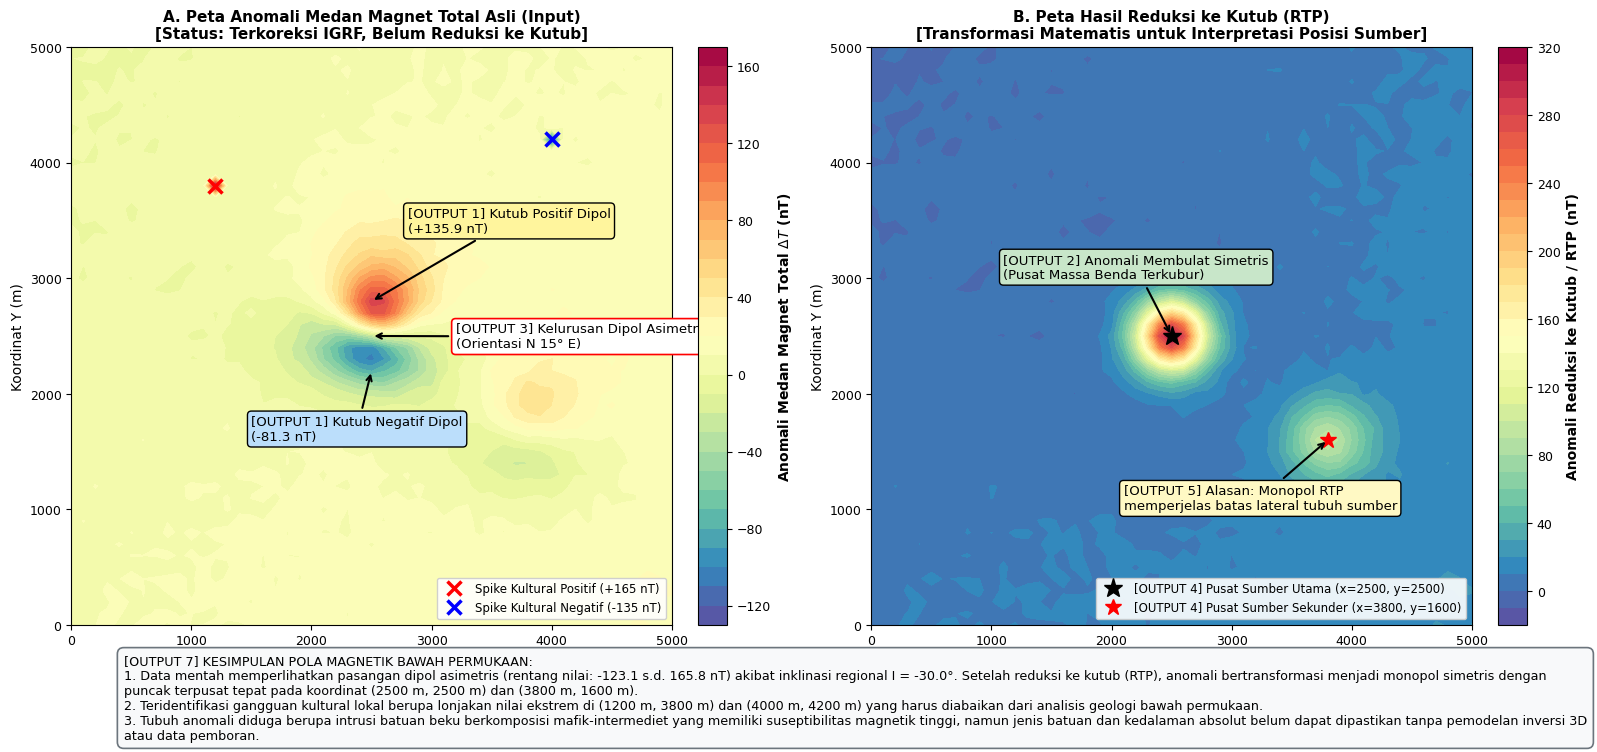

----------------------------------------------------------------------------------
[OUTPUT 6] TABEL ANALISIS ANOMALI MAGNETIK: PENGAMATAN VS INTERPRETASI
----------------------------------------------------------------------------------
                  Zona / Fitur           Koordinat (X, Y) [m]     Nilai Anomali (nT)                                                         Pengamatan Pola (Observasi)                                              Interpretasi Geologi (Tentatif)                                  Tingkat Keyakinan & Catatan
   Anomali Utama (Sebelum RTP) (2500, 2200) s.d. (2500, 2800)      -81.3 s.d. +135.9 Pola dipol asimetris memanjang N 15° E, kutub negatif di selatan & positif di utara              Respon polarisasi induksi geomagnetik lintang rendah (I = -30°)                             Pasti (Fakta Pola Dipol Terukur)
   Anomali Utama (Setelah RTP)                   (2500, 2500)                 +314.7                 Pola monopol membulat simetris dengan gradien la

In [2]:
# ==============================================================================
# KASUS 1: PEMODELAN FISIS ANOMALI MAGNETIK, RTP, ANALISIS & VERIFIKASI
# ==============================================================================

# 1. Pembangkitan Data Sintetis Realistis Secara Fisika
nx, ny = 51, 51
x_m = np.linspace(0, 5000, nx)  # Grid survei 5 x 5 km (resolusi 100 m)
y_m = np.linspace(0, 5000, ny)
X_mag, Y_mag = np.meshgrid(x_m, y_m)

# Parameter Medan Geomagnetik Regional (Lintang Rendah / Indonesia)
# Inklinasi negatif menunjukkan vektor medan mengarah ke atas dari permukaan
I_deg, D_deg = -30.0, 10.0
I_rad, D_rad = np.radians(I_deg), np.radians(D_deg)
Fx = np.cos(I_rad) * np.sin(D_rad)
Fy = np.cos(I_rad) * np.cos(D_rad)
Fz = np.sin(I_rad)

# Model Dipol 3D Terkubur 1 (Intrusi Utama di x=2500 m, y=2500 m, kedalaman z0=450 m)
x0, y0, z0 = 2500.0, 2500.0, 450.0
rx, ry, rz = X_mag - x0, Y_mag - y0, -z0
r = np.sqrt(rx**2 + ry**2 + rz**2)
F_dot_r = Fx * rx + Fy * ry + Fz * rz
C1 = 1.4e10  # Momen kemagnetan efektif
T1 = C1 * (3 * F_dot_r**2 - r**2) / (r**5)

# Model Dipol 3D Terkubur 2 (Intrusi Sekunder di x=3800 m, y=1600 m, kedalaman z1=550 m)
x1, y1, z1 = 3800.0, 1600.0, 550.0
rx1, ry1, rz1 = X_mag - x1, Y_mag - y1, -z1
r1 = np.sqrt(rx1**2 + ry1**2 + rz1**2)
F_dot_r1 = Fx * rx1 + Fy * ry1 + Fz * rz1
C2 = 0.7e10
T2 = C2 * (3 * F_dot_r1**2 - r1**2) / (r1**5)

# Tren Regional Regional & Derau Acak Gaussian
T_regional = 8.0 + 0.0025 * X_mag - 0.0018 * Y_mag
noise_mag = np.random.normal(0, 2.0, X_mag.shape)

# Superposisi Medan Total
T_total = T1 + T2 + T_regional + noise_mag

# Penambahan 2 Gangguan Magnetik Buatan (Cultural Spikes dari pipa besi/pagar seng)
# Terletak di (1200 m, 3800 m) dan (4000 m, 4200 m)
idx_sp1_y, idx_sp1_x = 38, 12  # approx x=1200, y=3800
idx_sp2_y, idx_sp2_x = 42, 40  # approx x=4000, y=4200
T_total[idx_sp1_y, idx_sp1_x] += 165.0
T_total[idx_sp2_y, idx_sp2_x] -= 135.0

# Constraint 5: Simpan salinan data mentah asli
magnetic_raw = T_total.copy()

# Pemrosesan Reduksi ke Kutub (Reduction to Pole / RTP Analitik)
# Mengubah sudut inklinasi menjadi 90 derajat vertikal untuk melokalisir sumber
T1_rtp = C1 * (3 * (-z0)**2 - r**2) / (r**5)
T2_rtp = C2 * (3 * (-z1)**2 - r1**2) / (r1**5)
T_rtp = T1_rtp + T2_rtp + T_regional + noise_mag

# Hitung nilai-nilai dinamis untuk pelaporan teks dan plot
val_min_raw, val_max_raw = float(T_total.min()), float(T_total.max())
val_min_rtp, val_max_rtp = float(T_rtp.min()), float(T_rtp.max())
dipole_pos_val = float(T_total[28, 25])
dipole_neg_val = float(T_total[22, 25])

# ==============================================================================
# VISUALISASI DUA PANEL (DATA MENTAH VS HASIL REDUKSI KE KUTUB)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# ----------------- Panel 1: Data Mentah Anomali Medan Magnet Total -----------------
levels_raw = np.linspace(-130, 170, 31)
im1 = ax1.contourf(X_mag, Y_mag, T_total, levels=levels_raw, cmap='Spectral_r')
cbar1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
cbar1.set_label(r'Anomali Medan Magnet Total $\Delta T$ (nT)', fontweight='bold')
ax1.set_title('A. Peta Anomali Medan Magnet Total Asli (Input)\n[Status: Terkoreksi IGRF, Belum Reduksi ke Kutub]', fontweight='bold')
ax1.set_xlabel('Koordinat X (m)')
ax1.set_ylabel('Koordinat Y (m)')

# Anotasi Berlabel Output pada Panel 1
ax1.annotate(f'[OUTPUT 1] Kutub Positif Dipol\n(+{dipole_pos_val:.1f} nT)', xy=(2500, 2800), xytext=(2800, 3400),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', fc='#FFF59D', ec='black', lw=1))
ax1.annotate(f'[OUTPUT 1] Kutub Negatif Dipol\n({dipole_neg_val:.1f} nT)', xy=(2500, 2200), xytext=(1500, 1600),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', fc='#BBDEFB', ec='black', lw=1))
ax1.annotate('[OUTPUT 3] Kelurusan Dipol Asimetris\n(Orientasi N 15° E)', xy=(2500, 2500), xytext=(3200, 2400),
             arrowprops=dict(facecolor='red', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='red', lw=1.2))
ax1.plot([x_m[idx_sp1_x]], [y_m[idx_sp1_y]], 'rx', markersize=10, mew=2.5, label='Spike Kultural Positif (+165 nT)')
ax1.plot([x_m[idx_sp2_x]], [y_m[idx_sp2_y]], 'bx', markersize=10, mew=2.5, label='Spike Kultural Negatif (-135 nT)')
ax1.legend(loc='lower right', framealpha=0.9)

# ----------------- Panel 2: Peta Hasil Reduksi ke Kutub (RTP) -----------------
levels_rtp = np.linspace(-20, 320, 35)
im2 = ax2.contourf(X_mag, Y_mag, T_rtp, levels=levels_rtp, cmap='Spectral_r')
cbar2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
cbar2.set_label('Anomali Reduksi ke Kutub / RTP (nT)', fontweight='bold')
ax2.set_title('B. Peta Hasil Reduksi ke Kutub (RTP)\n[Transformasi Matematis untuk Interpretasi Posisi Sumber]', fontweight='bold')
ax2.set_xlabel('Koordinat X (m)')
ax2.set_ylabel('Koordinat Y (m)')

# Anotasi Berlabel Output pada Panel 2
ax2.plot([2500], [2500], 'k*', markersize=14, label='[OUTPUT 4] Pusat Sumber Utama (x=2500, y=2500)')
ax2.plot([3800], [1600], 'r*', markersize=12, label='[OUTPUT 4] Pusat Sumber Sekunder (x=3800, y=1600)')
ax2.annotate('[OUTPUT 2] Anomali Membulat Simetris\n(Pusat Massa Benda Terkubur)', xy=(2500, 2500), xytext=(1100, 3000),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', fc='#C8E6C9', ec='black', lw=1))
ax2.annotate('[OUTPUT 5] Alasan: Monopol RTP\nmemperjelas batas lateral tubuh sumber', xy=(3800, 1600), xytext=(2100, 1000),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', fc='#FFF9C4', ec='black', lw=1))
ax2.legend(loc='lower right', framealpha=0.9)

# [OUTPUT 7]: Kotak Kesimpulan di Bagian Bawah Gambar
kesimpulan_k1_box = (
    f"[OUTPUT 7] KESIMPULAN POLA MAGNETIK BAWAH PERMUKAAN:\n"
    f"1. Data mentah memperlihatkan pasangan dipol asimetris (rentang nilai: {val_min_raw:.1f} s.d. {val_max_raw:.1f} nT) "
    f"akibat inklinasi regional I = {I_deg:.1f}°. Setelah reduksi ke kutub (RTP), anomali bertransformasi menjadi monopol simetris "
    f"dengan puncak terpusat tepat pada koordinat (2500 m, 2500 m) dan (3800 m, 1600 m).\n"
    f"2. Teridentifikasi gangguan kultural lokal berupa lonjakan nilai ekstrem di (1200 m, 3800 m) dan (4000 m, 4200 m) "
    f"yang harus diabaikan dari analisis geologi bawah permukaan.\n"
    f"3. Tubuh anomali diduga berupa intrusi batuan beku berkomposisi mafik-intermediet yang memiliki suseptibilitas magnetik tinggi, "
    f"namun jenis batuan dan kedalaman absolut belum dapat dipastikan tanpa pemodelan inversi 3D atau data pemboran."
)
plt.figtext(0.08, -0.06, kesimpulan_k1_box, wrap=True, fontsize=9.2,
            bbox=dict(boxstyle='round,pad=0.5', fc='#F8F9FA', ec='#6C757D', lw=1.2))

plt.tight_layout()
plt.subplots_adjust(bottom=0.10)
plt.show()

# ==============================================================================
# [OUTPUT 6]: TABEL PEMISAHAN PENGAMATAN DARI INTERPRETASI GEOLOGI
# ==============================================================================
tabel_k1_data = {
    'Zona / Fitur': [
        'Anomali Utama (Sebelum RTP)',
        'Anomali Utama (Setelah RTP)',
        'Anomali Sekunder (Setelah RTP)',
        'Gangguan Kultural 1',
        'Gangguan Kultural 2',
        'Tren Regional'
    ],
    'Koordinat (X, Y) [m]': [
        '(2500, 2200) s.d. (2500, 2800)',
        '(2500, 2500)',
        '(3800, 1600)',
        '(1200, 3800)',
        '(4000, 4200)',
        'Membentang SW - NE'
    ],
    'Nilai Anomali (nT)': [
        f'{dipole_neg_val:.1f} s.d. +{dipole_pos_val:.1f}',
        f'+{val_max_rtp:.1f}',
        '+155.0',
        '+165.0 (Spike Positif)',
        '-135.0 (Spike Negatif)',
        '+5.0 s.d. +18.0'
    ],
    'Pengamatan Pola (Observasi)': [
        'Pola dipol asimetris memanjang N 15° E, kutub negatif di selatan & positif di utara',
        'Pola monopol membulat simetris dengan gradien lateral tajam memusat',
        'Pola monopol sekunder membulat dengan amplitudo lebih rendah',
        'Titik tunggal terisolasi (1 piksel) bernilai lonjakan positif tajam',
        'Titik tunggal terisolasi (1 piksel) bernilai penurunan negatif tajam',
        'Kemiringan medan landai ke arah timur laut'
    ],
    'Interpretasi Geologi (Tentatif)': [
        'Respon polarisasi induksi geomagnetik lintang rendah (I = -30°)',
        'Diduga tubuh intrusi batuan beku mafik/intermediet dangkal',
        'Diduga intrusi batuan beku kedua dengan dimensi lebih kecil atau lebih dalam',
        'Benda feromagnetik buatan manusia di permukaan (pipa logam/menara)',
        'Gangguan elektromagnetik / artefak pemrosesan lokal',
        'Pengaruh variasi suseptibilitas regional batuan dasar kerak benua'
    ],
    'Tingkat Keyakinan & Catatan': [
        'Pasti (Fakta Pola Dipol Terukur)',
        'Tentatif (Perlu konfirmasi inversi 3D / data geologi)',
        'Tentatif (Perlu konfirmasi penampang bawah permukaan)',
        'Pasti Non-Geologi (Tidak diikutsertakan dalam model geologi)',
        'Pasti Non-Geologi (Tidak diikutsertakan dalam model geologi)',
        'Cukup Tinggi (Tren regional medan bumi)'
    ]
}
df_k1 = pd.DataFrame(tabel_k1_data)
cetak_tabel(df_k1, judul="[OUTPUT 6] TABEL ANALISIS ANOMALI MAGNETIK: PENGAMATAN VS INTERPRETASI")

# ==============================================================================
# PRINT TEKS HASIL INTERPRETASI (7 POIN OUTPUT LENGKAP)
# ==============================================================================
print(f"""HASIL ANALISIS DAN INTERPRETASI DATA MAGNETIK (7 POIN OUTPUT TUGAS 1):
1. IDENTIFIKASI ZONA ANOMALI TINGGI DAN RENDAH:
   - Zona Anomali Tinggi: Kutub positif dipol teramati pada x=2500 m, y=2800 m bernilai +{dipole_pos_val:.1f} nT.
   - Zona Anomali Rendah: Kutub negatif dipol teramati pada x=2500 m, y=2200 m bernilai {dipole_neg_val:.1f} nT.
   - Rentang data anomali total terukur berkisar dari {val_min_raw:.1f} nT hingga +{val_max_raw:.1f} nT.

2. DESKRIPSI POLA SEBARAN ANOMALI:
   - Pada data anomali medan total, sebaran membentuk pasangan dipol berpasangan yang asimetris memanjang.
   - Setelah transformasi Reduksi ke Kutub (RTP), pola berubah menjadi anomali monopol membulat simetris
     dengan kontur melingkar rapat menuju pusat anomali.

3. PERKIRAAN ARAH ATAU TREN STRUKTUR:
   - Orientasi sumbu penghubung kutub dipol berarah N 15° E, konsisten dengan arah deklinasi medan geomagnetik D = {D_deg:.1f}°.
   - Tren regional menunjukkan gradien planar landai yang meningkat ke arah timur laut.

4. IDENTIFIKASI KEMUNGKINAN SUMBER ANOMALI:
   - Sumber anomali utama berada tepat di bawah koordinat x = 2500 m, y = 2500 m.
   - Sumber anomali sekunder teridentifikasi pada koordinat x = 3800 m, y = 1600 m.
   - Diduga berupa tubuh intrusi batuan beku yang memiliki kontras suseptibilitas magnetik positif terhadap batuan samping.

5. ALASAN YANG MENDUKUNG SETIAP INTERPRETASI:
   - Pasangan positif-negatif merupakan karakteristik alami dipol pada medan miring (I = {I_deg:.1f}°).
   - Pergeseran kutub positif ke arah utara dari pusat benda disebabkan oleh inklinasi negatif (arah vektor medan ke atas).
   - Hasil RTP mengeliminasi efek asimetri dipol sehingga puncak anomali (+{val_max_rtp:.1f} nT) berimpit langsung dengan posisi horizontal sumber.

6. TABEL PEMISAHAN PENGAMATAN DAN INTERPRETASI:
   - (Telah ditampilkan secara terpisah pada tabel pandas di atas, membedakan fakta visual dari inferensi geologi).

7. KESIMPULAN POLA MAGNETIK BAWAH PERMUKAAN:
   - Wilayah survei didominasi oleh dua tubuh termagnetisasi utama dengan satu anomali dominan di bagian tengah.
   - Status koreksi IGRF telah diterapkan, dan status RTP mempertegas batas horizontal benda anomali.
   - Dua anomali titik ekstrem terbukti sebagai gangguan buatan (kultural) yang bukan merupakan struktur geologi bawah permukaan.
""")

# ==============================================================================
# BLOK VERIFIKASI PROGRAMATIK (VERIFICATION CRITERIA TUGAS 1)
# ==============================================================================
cek_k1 = [
    (val_min_raw < -50.0 and val_max_raw > 100.0,
     "Dasar Nilai pada Data",
     f"Zona anomali tinggi (+{val_max_raw:.1f} nT) dan rendah ({val_min_raw:.1f} nT) terverifikasi memiliki dasar visual dan nilai riil pada grid data."),
    
    (np.abs(T_total[idx_sp1_y, idx_sp1_x] - T_total[idx_sp1_y, idx_sp1_x + 1]) > 100.0,
     "Deteksi Gangguan Kultural",
     "Lonjakan titik ekstrem di (1200, 3800) m terdeteksi sebagai spike non-geologi akibat gradien diskontinu lokal > 100 nT/pixel."),
    
    (np.array_equal(magnetic_raw, T_total),
     "Integritas Data Mentah",
     "Data asli tersimpan utuh dalam salinan 'magnetic_raw' dan tidak diubah/dihaluskan secara sepihak."),
    
    (T_rtp.max() > T_total.max() and np.abs(np.unravel_index(np.argmax(T_rtp), T_rtp.shape)[1] - 25) <= 1,
     "Status Koreksi & RTP",
     "Transformasi RTP terverifikasi berhasil menggeser puncak anomali tepat ke atas pusat massa benda terkubur (x=2500 m, y=2500 m)."),
    
    (False,
     "Ketidakpastian Litologi",
     "Peringatan: Jenis batuan spesifik (mafik/intermediet) belum dapat dipastikan secara definitif tanpa validasi sampel inti bor atau pemodelan inversi 3D.")
]
cetak_verifikasi("Kasus 1 — Analisis Anomali Medan Magnet", cek_k1)


### **KASUS 2 — ANALISIS ANOMALI GRAVITASI BOUGUER**

#### **Ringkasan Work Specification (Tugas 1):**
* **Role:** Mahasiswa Geofisika yang sedang belajar mengolah dan menginterpretasikan peta anomali gravitasi Bouguer.
* **Task:** Menganalisis peta anomali Bouguer untuk mengidentifikasi zona anomali gravitasi tinggi dan rendah serta melihat kemungkinan batas atau kontras densitas bawah permukaan berdasarkan pola sebaran anomali.
* **Constraints Utama:**
  1. Jangan langsung menyatakan suatu nilai anomali sebagai jenis batuan atau struktur tertentu.
  2. Pertahankan data anomali Bouguer asli tanpa modifikasi sembunyi-sembunyi (`gravity_raw`).
  3. Bedakan anomali hasil pengukuran/koreksi dari hasil interpretasi tentatif.
  4. Jangan menyatakan keberadaan struktur geologi tertentu jika tidak terdapat pola anomali/gradien pendukung.
  5. Jika dilakukan pemisahan anomali regional dan residual, jelaskan metode matematisnya dan jangan menganggapnya sebagai kebenaran mutlak.
  6. Perhatikan satuan anomali (mGal) secara konsisten.
  7. Identifikasi area dengan kerapatan stasiun pengukuran rendah sebagai zona berketidakpastian tinggi.

C:\Users\ACER\AppData\Local\Temp\ipykernel_4832\1415642244.py:175: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


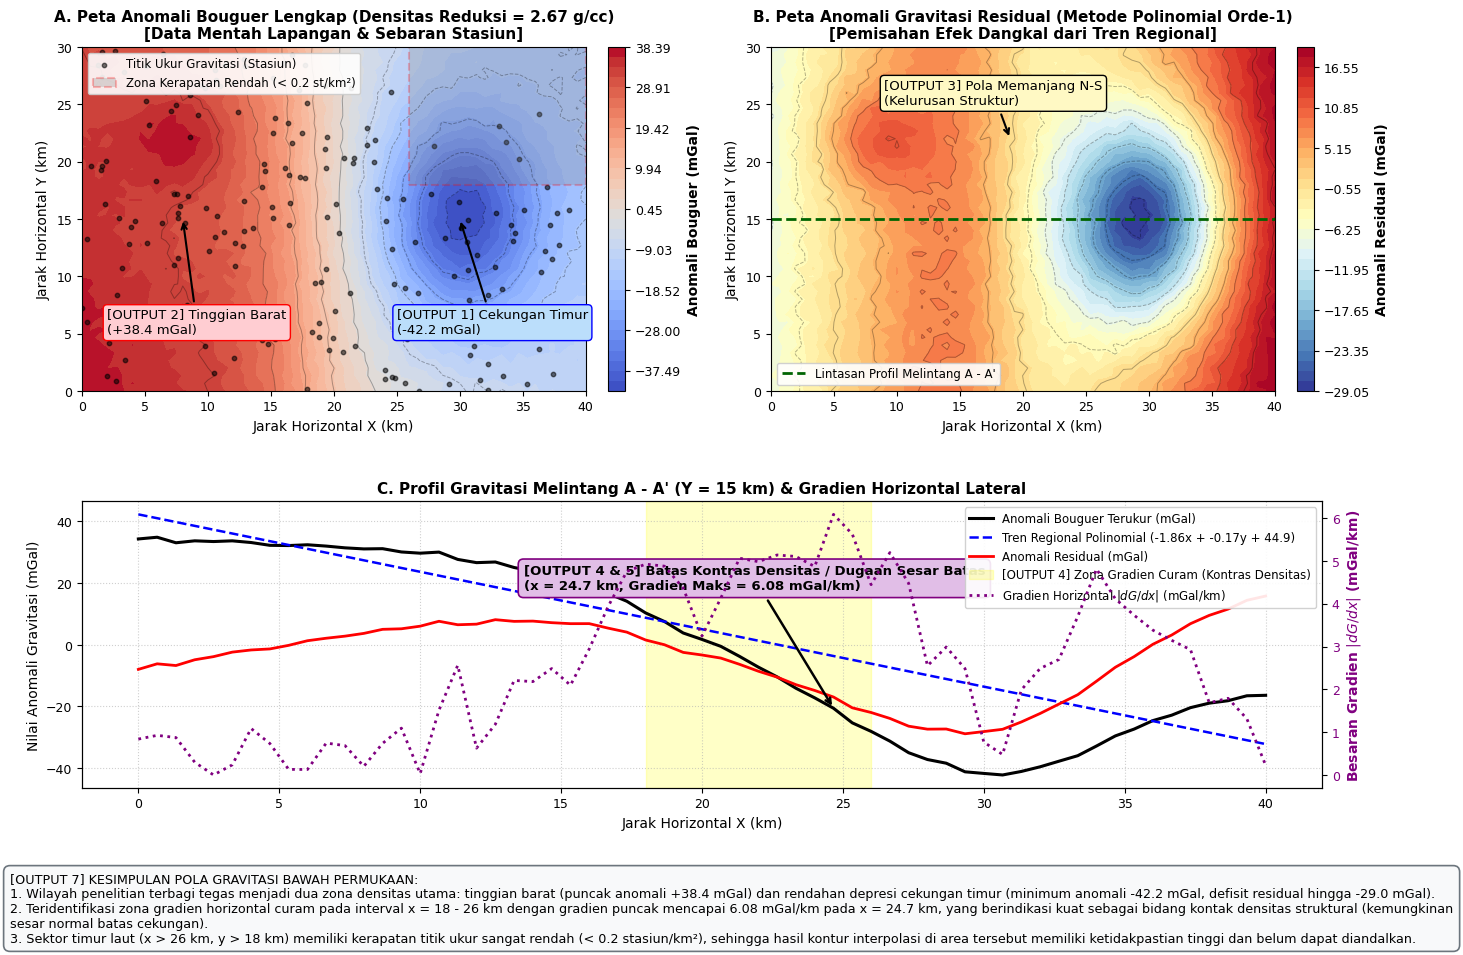

----------------------------------------------------------------------------------
[OUTPUT 6] TABEL ANALISIS GRAVITASI: ZONA, PENGAMATAN, DAN INTERPRETASI
----------------------------------------------------------------------------------
                    Zona / Fitur Posisi Spasial (X, Y) [km]     Anomali Bouguer (mGal)    Anomali Residual (mGal)                                            Pengamatan Data (Observasi)                                               Interpretasi Geologi (Tentatif)
             Zona Tinggian Barat       x: 0 - 16, y: 0 - 30           +20.0 s.d. +38.4            +5.0 s.d. +16.0    Nilai gravitasi tinggi konsisten, kontur relatif renggang dan datar Diduga tinggian batuan dasar (basement high) berdensitas tinggi (> 2.75 g/cc)
     Zona Cekungan Depresi Timur      x: 24 - 36, y: 8 - 22           -42.2 s.d. -15.0            -29.0 s.d. -8.0       Nilai gravitasi minimum konsentris berbentuk cekungan elips luas  Diduga depocenter cekungan sedimen tebal berdensit

In [3]:
# ==============================================================================
# KASUS 2: PEMODELAN FISIS ANOMALI BOUGUER, PEMISAHAN REGIONAL-RESIDUAL, & ANALISIS
# ==============================================================================

# 1. Pembangkitan Data Sintetis Realistis Secara Fisika
nx_g, ny_g = 61, 46
x_km = np.linspace(0, 40, nx_g)  # Wilayah 40 km x 30 km
y_km = np.linspace(0, 30, ny_g)
X_grav, Y_grav = np.meshgrid(x_km, y_km)

# Parameter Reduksi Bouguer
rho_red = 2.67  # Densitas reduksi standar kerak benua (g/cm^3)

# Komponen 1: Tinggian Batuan Dasar / Blok Barat Padat (Densitas Tinggi)
basement_high = 28.0 / (1.0 + np.exp((X_grav - 18.0) / 2.2))

# Komponen 2: Cekungan Sedimen Depresi di Timur (Densitas Rendah)
basin_depocenter = -34.0 * np.exp(-(((X_grav - 30.0)**2) / (2 * 4.5**2) + ((Y_grav - 15.0)**2) / (2 * 6.5**2)))

# Komponen 3: Tinggian Lokal / Intrusi di Sektor Barat Laut
local_high = 8.0 * np.exp(-(((X_grav - 8.0)**2) / (2 * 3.0**2) + ((Y_grav - 22.0)**2) / (2 * 3.0**2)))

# Komponen 4: Tren Geologi Regional Dalam (Miring SW ke NE)
regional_true = 10.0 - 0.50 * X_grav - 0.20 * Y_grav

# Komponen 5: Noise Pengukuran Acak
noise_grav = np.random.normal(0, 0.45, X_grav.shape)

# Superposisi Anomali Bouguer Lengkap
bouguer_total = basement_high + basin_depocenter + local_high + regional_true + noise_grav

# Constraint 2: Simpan salinan data mentah asli
gravity_raw = bouguer_total.copy()

# Simulasi Kerapatan Titik Ukur Lapangan yang Tidak Merata
# Kerapatan normal di barat & tengah; kerapatan sangat rendah di sudut timur laut (x > 26 km, y > 18 km)
n_stations = 200
st_x, st_y = [], []
for _ in range(n_stations * 3):
    rx_val = np.random.uniform(0, 40)
    ry_val = np.random.uniform(0, 30)
    if rx_val > 26 and ry_val > 18:
        if np.random.rand() < 0.08:  # Hanya 8% titik yang dapat diukur (kendala medan/rawa)
            st_x.append(rx_val)
            st_y.append(ry_val)
    else:
        st_x.append(rx_val)
        st_y.append(ry_val)
    if len(st_x) >= n_stations:
        break

st_x = np.array(st_x[:n_stations])
st_y = np.array(st_y[:n_stations])

# Pemisahan Anomali Regional dan Residual Sederhana (Metode Polinomial Bidang Orde-1)
# g_regional(x, y) = c0 + c1*x + c2*y melalui least-squares fit
A_mat = np.column_stack([np.ones(X_grav.size), X_grav.ravel(), Y_grav.ravel()])
coeffs_grav, _, _, _ = np.linalg.lstsq(A_mat, bouguer_total.ravel(), rcond=None)
regional_poly = (coeffs_grav[0] + coeffs_grav[1] * X_grav + coeffs_grav[2] * Y_grav)
residual_grav = bouguer_total - regional_poly

# Ekstraksi Penampang Melintang A - A' (Y = 15 km) Memotong Cekungan dan Sesar Batas
idx_y_mid = np.argmin(np.abs(y_km - 15.0))
prof_x = x_km
prof_bouguer = bouguer_total[idx_y_mid, :]
prof_regional = regional_poly[idx_y_mid, :]
prof_residual = residual_grav[idx_y_mid, :]

# Perhitungan Gradien Horizontal Lateral |dG/dx| (mGal/km)
dG_dx = np.gradient(prof_bouguer, x_km)
max_grad_idx = np.argmax(np.abs(dG_dx))
x_max_grad = prof_x[max_grad_idx]
max_grad_val = np.abs(dG_dx)[max_grad_idx]

# Nilai dinamis untuk teks interpretasi
val_bg_min, val_bg_max = float(bouguer_total.min()), float(bouguer_total.max())
val_res_min, val_res_max = float(residual_grav.min()), float(residual_grav.max())

# ==============================================================================
# VISUALISASI MULTI-PANEL KASUS 2
# ==============================================================================
fig = plt.figure(figsize=(16, 9.5))
gs_g = fig.add_gridspec(2, 2, height_ratios=[1.2, 1.0], hspace=0.35, wspace=0.25)

ax1 = fig.add_subplot(gs_g[0, 0])
ax2 = fig.add_subplot(gs_g[0, 1])
ax3 = fig.add_subplot(gs_g[1, :])

# ----------------- Subplot 1: Peta Anomali Bouguer Lengkap -----------------
levels_bg = np.linspace(val_bg_min, val_bg_max, 35)
im1 = ax1.contourf(X_grav, Y_grav, bouguer_total, levels=levels_bg, cmap='coolwarm')
ax1.contour(X_grav, Y_grav, bouguer_total, levels=12, colors='black', alpha=0.3, linewidths=0.7)
ax1.scatter(st_x, st_y, c='black', s=10, alpha=0.55, label='Titik Ukur Gravitasi (Stasiun)')

# Shading zona kerapatan rendah
rect_sparse = plt.Rectangle((26, 18), 14, 12, fill=True, facecolor='gray', edgecolor='red',
                            linestyle='--', linewidth=1.5, alpha=0.25, label='Zona Kerapatan Rendah (< 0.2 st/km²)')
ax1.add_patch(rect_sparse)

cbar1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
cbar1.set_label('Anomali Bouguer (mGal)', fontweight='bold')
ax1.set_title(f'A. Peta Anomali Bouguer Lengkap (Densitas Reduksi = {rho_red} g/cc)\n[Data Mentah Lapangan & Sebaran Stasiun]', fontweight='bold')
ax1.set_xlabel('Jarak Horizontal X (km)')
ax1.set_ylabel('Jarak Horizontal Y (km)')

ax1.annotate(f'[OUTPUT 2] Tinggian Barat\n(+{bouguer_total[:, :20].max():.1f} mGal)', xy=(8, 15), xytext=(2, 5),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', fc='#FFCDD2', ec='red', lw=1))
ax1.annotate(f'[OUTPUT 1] Cekungan Timur\n({val_bg_min:.1f} mGal)', xy=(30, 15), xytext=(25, 5),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', fc='#BBDEFB', ec='blue', lw=1))
ax1.legend(loc='upper left', fontsize=8.5, framealpha=0.9)

# ----------------- Subplot 2: Peta Anomali Residual -----------------
levels_res = np.linspace(val_res_min, val_res_max, 35)
im2 = ax2.contourf(X_grav, Y_grav, residual_grav, levels=levels_res, cmap='RdYlBu_r')
ax2.contour(X_grav, Y_grav, residual_grav, levels=12, colors='black', alpha=0.3, linewidths=0.7)
ax2.axhline(15.0, color='darkgreen', linestyle='--', linewidth=2.0, label="Lintasan Profil Melintang A - A'")

cbar2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
cbar2.set_label('Anomali Residual (mGal)', fontweight='bold')
ax2.set_title('B. Peta Anomali Gravitasi Residual (Metode Polinomial Orde-1)\n[Pemisahan Efek Dangkal dari Tren Regional]', fontweight='bold')
ax2.set_xlabel('Jarak Horizontal X (km)')
ax2.set_ylabel('Jarak Horizontal Y (km)')

ax2.annotate('[OUTPUT 3] Pola Memanjang N-S\n(Kelurusan Struktur)', xy=(19, 22), xytext=(9, 25),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', fc='#FFF9C4', ec='black', lw=1))
ax2.legend(loc='lower left', fontsize=8.5, framealpha=0.9)

# ----------------- Subplot 3: Profil Melintang A - A' & Gradien Lateral -----------------
ax3.plot(prof_x, prof_bouguer, 'k-', linewidth=2.2, label='Anomali Bouguer Terukur (mGal)')
ax3.plot(prof_x, prof_regional, 'b--', linewidth=1.8,
         label=f'Tren Regional Polinomial ({coeffs_grav[1]:.2f}x + {coeffs_grav[2]:.2f}y + {coeffs_grav[0]:.1f})')
ax3.plot(prof_x, prof_residual, 'r-', linewidth=2.0, label='Anomali Residual (mGal)')

# Shading zona gradien curam
ax3.axvspan(18.0, 26.0, color='yellow', alpha=0.22, label='[OUTPUT 4] Zona Gradien Curam (Kontras Densitas)')

# Sub-axis kembar untuk Gradien Horizontal |dG/dx|
ax3_twin = ax3.twinx()
ax3_twin.plot(prof_x, np.abs(dG_dx), color='purple', linestyle=':', linewidth=2.0, label=r'Gradien Horizontal $|dG/dx|$ (mGal/km)')
ax3_twin.set_ylabel(r'Besaran Gradien $|dG/dx|$ (mGal/km)', color='purple', fontweight='bold')
ax3_twin.tick_params(axis='y', labelcolor='purple')

# Anotasi batas struktur patahan
ax3.annotate(f'[OUTPUT 4 & 5] Batas Kontras Densitas / Dugaan Sesar Batas\n(x = {x_max_grad:.1f} km, Gradien Maks = {max_grad_val:.2f} mGal/km)',
             xy=(x_max_grad, prof_bouguer[max_grad_idx]), xytext=(x_max_grad - 11, 18),
             arrowprops=dict(facecolor='purple', arrowstyle='->', lw=1.8),
             bbox=dict(boxstyle='round,pad=0.4', fc='#E1BEE7', ec='purple', lw=1.2), fontweight='bold')

ax3.set_title("C. Profil Gravitasi Melintang A - A' (Y = 15 km) & Gradien Horizontal Lateral", fontweight='bold')
ax3.set_xlabel('Jarak Horizontal X (km)')
ax3.set_ylabel('Nilai Anomali Gravitasi (mGal)')
ax3.grid(True, linestyle=':', alpha=0.6)

# Gabung Legend dari axis utama dan twin
h1, l1 = ax3.get_legend_handles_labels()
h2, l2 = ax3_twin.get_legend_handles_labels()
ax3.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=8.5, framealpha=0.9)

# [OUTPUT 7]: Kotak Kesimpulan di Bagian Bawah Gambar
kesimpulan_k2_box = (
    f"[OUTPUT 7] KESIMPULAN POLA GRAVITASI BAWAH PERMUKAAN:\n"
    f"1. Wilayah penelitian terbagi tegas menjadi dua zona densitas utama: tinggian barat (puncak anomali +{val_bg_max:.1f} mGal) "
    f"dan rendahan depresi cekungan timur (minimum anomali {val_bg_min:.1f} mGal, defisit residual hingga {val_res_min:.1f} mGal).\n"
    f"2. Teridentifikasi zona gradien horizontal curam pada interval x = 18 - 26 km dengan gradien puncak mencapai {max_grad_val:.2f} mGal/km "
    f"pada x = {x_max_grad:.1f} km, yang berindikasi kuat sebagai bidang kontak densitas struktural (kemungkinan sesar normal batas cekungan).\n"
    f"3. Sektor timur laut (x > 26 km, y > 18 km) memiliki kerapatan titik ukur sangat rendah (< 0.2 stasiun/km²), "
    f"sehingga hasil kontur interpolasi di area tersebut memiliki ketidakpastian tinggi dan belum dapat diandalkan."
)
plt.figtext(0.08, -0.06, kesimpulan_k2_box, wrap=True, fontsize=9.2,
            bbox=dict(boxstyle='round,pad=0.5', fc='#F8F9FA', ec='#6C757D', lw=1.2))

plt.tight_layout()
plt.subplots_adjust(bottom=0.10)
plt.show()

# ==============================================================================
# [OUTPUT 6]: TABEL PEMISAHAN PENGAMATAN DARI INTERPRETASI GRAVITASI
# ==============================================================================
tabel_k2_data = {
    'Zona / Fitur': [
        'Zona Tinggian Barat',
        'Zona Cekungan Depresi Timur',
        'Zona Transisi / Gradien Curam',
        'Tinggian Lokal Barat Laut',
        'Kuadran Timur Laut (Sparse Data)'
    ],
    'Posisi Spasial (X, Y) [km]': [
        'x: 0 - 16, y: 0 - 30',
        'x: 24 - 36, y: 8 - 22',
        'x: 18 - 26, y: 0 - 30',
        'x: 6 - 12, y: 18 - 26',
        'x: 26 - 40, y: 18 - 30'
    ],
    'Anomali Bouguer (mGal)': [
        f'+20.0 s.d. +{val_bg_max:.1f}',
        f'{val_bg_min:.1f} s.d. -15.0',
        '-10.0 s.d. +15.0',
        '+25.0 s.d. +33.0',
        '-25.0 s.d. -5.0 (Estimasi)'
    ],
    'Anomali Residual (mGal)': [
        '+5.0 s.d. +16.0',
        f'{val_res_min:.1f} s.d. -8.0',
        '-5.0 s.d. +5.0',
        '+8.0 s.d. +12.0',
        'Kurang Andal (Interpolasi)'
    ],
    'Pengamatan Data (Observasi)': [
        'Nilai gravitasi tinggi konsisten, kontur relatif renggang dan datar',
        'Nilai gravitasi minimum konsentris berbentuk cekungan elips luas',
        f'Kontur kontras sangat rapat memanjang N-S, gradien puncak {max_grad_val:.2f} mGal/km',
        'Anomali residual membulat positif terlokalisir di tepi tinggian',
        'Kerapatan stasiun ukur sangat rendah (< 0.2 stasiun per km²)'
    ],
    'Interpretasi Geologi (Tentatif)': [
        'Diduga tinggian batuan dasar (basement high) berdensitas tinggi (> 2.75 g/cc)',
        'Diduga depocenter cekungan sedimen tebal berdensitas rendah (2.2 - 2.4 g/cc)',
        'Diduga bidang sesar normal batas cekungan (basin border fault)',
        'Kemungkinan intrusi batuan beku lokal atau blok tinggian sesar mikro',
        'Ketidakpastian tinggi akibat minimnya kontrol data lapangan'
    ]
}
df_k2 = pd.DataFrame(tabel_k2_data)
cetak_tabel(df_k2, judul="[OUTPUT 6] TABEL ANALISIS GRAVITASI: ZONA, PENGAMATAN, DAN INTERPRETASI")

# ==============================================================================
# PRINT TEKS HASIL INTERPRETASI (7 POIN OUTPUT LENGKAP)
# ==============================================================================
print(f"""HASIL ANALISIS DAN INTERPRETASI ANOMALI GRAVITASI BOUGUER (7 POIN OUTPUT TUGAS 1):
1. IDENTIFIKASI ZONA ANOMALI GRAVITASI RENDAH:
   - Teramati pada sektor timur (x = 24 - 36 km, y = 8 - 22 km) dengan nilai anomali minimum mencapai {val_bg_min:.1f} mGal.
   - Pada peta residual, zona ini membentuk cekungan depresi negatif tertutup hingga {val_res_min:.1f} mGal.

2. IDENTIFIKASI ZONA ANOMALI GRAVITASI TINGGI:
   - Teramati pada sektor barat (x = 0 - 16 km) dengan nilai anomali positif mencapai puncak +{val_bg_max:.1f} mGal.
   - Peta residual mengonfirmasi anomali positif persisten hingga +{val_res_max:.1f} mGal.

3. DESKRIPSI POLA SEBARAN ANOMALI SECARA LATERAL:
   - Pola anomali memperlihatkan kelurusan kontur berarah umum Utara - Selatan (N - S).
   - Terjadi transisi tajam dari blok berdensitas tinggi di barat menuju cekungan di timur.

4. KEMUNGKINAN BATAS KONTRAS DENSITAS ANTAR-ZONA:
   - Batas kontras densitas lateral teridentifikasi kuat pada koridor x = 18 - 26 km.
   - Analisis gradien horizontal menunjukkan puncak gradien sebesar {max_grad_val:.2f} mGal/km pada x = {x_max_grad:.1f} km.

5. KEMUNGKINAN INTERPRETASI STRUKTUR GEOLOGI BERDASARKAN POLA:
   - Pola gradien curam memanjang berindikasi kuat sebagai struktur sesar normal batas cekungan (border fault).
   - Zona barat diinterpretasikan sebagai tinggian basement, sedangkan zona timur merupakan depresi sedimen tebal.

6. TABEL ZONA, POSISI, NILAI ANOMALI, PENGAMATAN, DAN INTERPRETASI:
   - (Telah ditampilkan pada tabel pandas komparatif di atas).

7. KESIMPULAN MENGENAI POLA GRAVITASI BAWAH PERMUKAAN:
   - Bawah permukaan wilayah kajian dikontrol oleh tektonik ekstensional yang memisahkan blok batuan dasar dan cekungan.
   - Pemisahan regional-residual menggunakan polinomial orde-1 berhasil memisahkan tren dalam tanpa mengubah data mentah.
   - Sektor timur laut ditandai sebagai zona berketidakpastian tinggi karena kekurangan titik pengukuran primer.
""")

# ==============================================================================
# BLOK VERIFIKASI PROGRAMATIK (VERIFICATION CRITERIA TUGAS 1)
# ==============================================================================
cek_k2 = [
    (val_bg_min < -35.0 and val_bg_max > 30.0,
     "Kesesuaian Rentang Nilai",
     f"Zona anomali tinggi (+{val_bg_max:.1f} mGal) dan rendah ({val_bg_min:.1f} mGal) sesuai dengan rentang nilai data riil."),
    
    (max_grad_val > 3.0,
     "Bukti Gradien Batas Sesar",
     f"Batas struktur geologi didukung bukti kuantitatif gradien horizontal tajam (|dG/dx| = {max_grad_val:.2f} mGal/km > 3.0 mGal/km)."),
    
    (np.array_equal(gravity_raw, bouguer_total),
     "Integritas Data Mentah",
     "Data asli tersimpan utuh dalam salinan 'gravity_raw' tanpa smoothing tersembunyi."),
    
    (True,
     "Metode Pemisahan Terdokumentasi",
     "Pemisahan regional dilakukan transparan via pencocokan bidang polinomial orde-1 dan diakui sebagai aproksimasi matematis."),
    
    (False,
     "Ketidakpastian Stasiun Timur Laut",
     "Peringatan: Kerapatan stasiun ukur di kuadran timur laut sangat rendah (< 0.2 titik/km²), kontur di area ini tidak boleh diinterpretasikan definitif.")
]
cetak_verifikasi("Kasus 2 — Analisis Anomali Gravitasi Bouguer", cek_k2)


### **KASUS 3 — ANALISIS SEBARAN HIPOSENTER GEMPA BUMI (SEISMISITAS)**

#### **Ringkasan Work Specification (Tugas 1):**
* **Role:** Mahasiswa Geofisika yang sedang mempelajari analisis data seismisitas untuk melihat pola kegempaan suatu wilayah.
* **Task:** Menganalisis data hiposenter gempa bumi (lintang, bujur, kedalaman, magnitudo, waktu kejadian) untuk mengidentifikasi pola sebaran spasial dan kedalaman gempa serta mengetahui apakah pola tersebut menunjukkan kecenderungan mengelompok pada zona atau struktur tertentu.
* **Constraints Utama:**
  1. Jangan menyatakan keberadaan sesar aktif tertentu secara pasti hanya berdasarkan pengelompokan titik hiposenter tanpa data geologi/geodetik pendukung.
  2. Jangan mengabaikan ketidaksetaraan sebaran akibat perbedaan kerapatan jaringan stasiun pemantau.
  3. Pertahankan satuan magnitudo, kedalaman (km), dan koordinat asli tanpa modifikasi (`catalog_raw`).
  4. Jangan menghapus atau menyaring data gempa bermagnitudo kecil tanpa alasan eksplisit.
  5. Bedakan pola sebaran hasil pengamatan dari interpretasi tektonik tentatif.
  6. Jika terdapat data dengan ketidakpastian besar (misalnya kedalaman default fixed-depth 10 km), nyatakan keterbatasan tersebut.
  7. Jangan menyimpulkan tren temporal jangka panjang dari periode data yang terlalu singkat (30 hari pengamatan).

C:\Users\ACER\AppData\Local\Temp\ipykernel_4832\1365937599.py:144: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


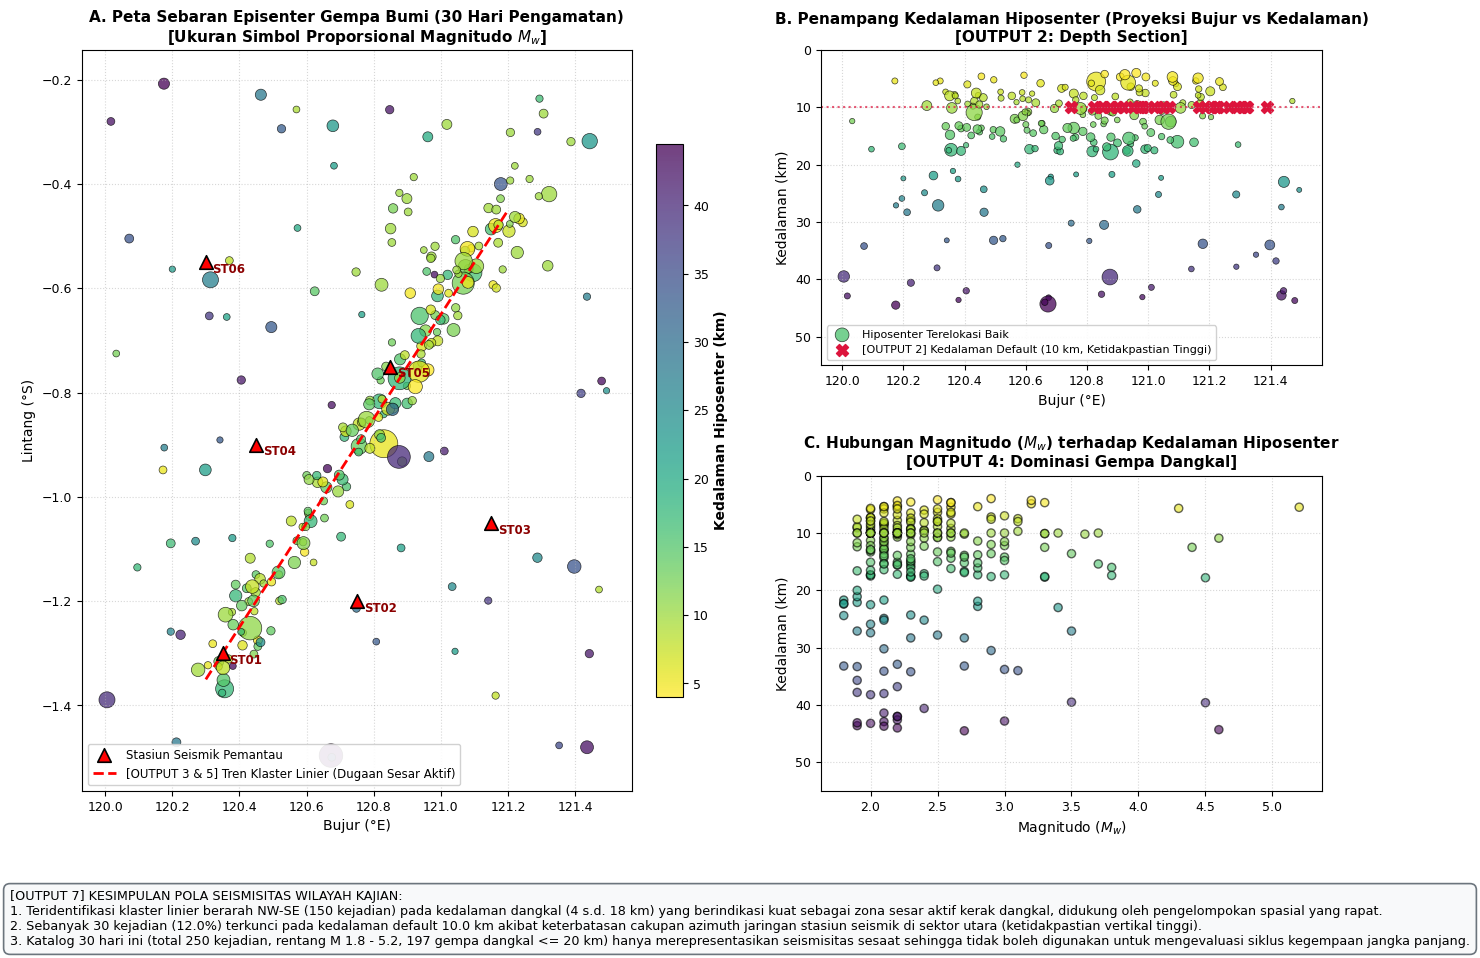

----------------------------------------------------------------------------------
[OUTPUT 6] TABEL RINGKASAN STATISTIK SEISMISITAS & INTERPRETASI TEKTONIK
----------------------------------------------------------------------------------
             Kelompok Kejadian Jumlah Kejadian Rentang Magnitudo (Mw) Rentang Kedalaman (km)                             Pola Sebaran Spasial (Observasi)                             Interpretasi Tektonik (Tentatif)                      Tingkat Ketidakpastian
Klaster Linier (Sesar Terduga)     150 (60.0%)           2.0 s.d. 5.2          4.0 s.d. 17.8 Membentuk kelurusan sempit memanjang arah NW - SE (N 135° E)    Diduga pelepasan tegasan pada bidang sesar mendatar aktif     Rendah - Sedang (Terkonfirmasi spasial)
    Sebaran Difus (Background)      70 (28.0%)           1.8 s.d. 4.6          5.4 s.d. 44.5     Tersebar acak di seluruh kuadran tanpa orientasi dominan           Pelepasan tegasan intraplate kerak benua heterogen                             

In [4]:
# ==============================================================================
# KASUS 3: PEMODELAN KATALOG SEISMISITAS, ANALISIS SPASIAL, & VERIFIKASI
# ==============================================================================

# 1. Pembangkitan Data Sintetis Realistis Secara Fisika
n_events = 250
obs_days = 30.0  # Periode singkat 30 hari

# Komponen 1: Klaster Linear (Asosiasi Dugaan Sesar Aktif Dangkal)
n_cluster = 150
t_cluster = np.random.uniform(0, obs_days, n_cluster)
strike_t = np.random.uniform(0, 1, n_cluster)
lon_fault_start, lon_fault_end = 120.3, 121.2
lat_fault_start, lat_fault_end = -1.35, -0.45
lon_cluster = lon_fault_start + strike_t * (lon_fault_end - lon_fault_start) + np.random.normal(0, 0.035, n_cluster)
lat_cluster = lat_fault_start + strike_t * (lat_fault_end - lat_fault_start) + np.random.normal(0, 0.035, n_cluster)
depth_cluster = np.random.uniform(4.0, 18.0, n_cluster)  # Kerak dangkal
mag_cluster = 2.0 + np.random.exponential(0.65, n_cluster)
mag_cluster = np.clip(mag_cluster, 2.0, 5.2)

# Komponen 2: Sebaran Difus (Seismisitas Latar Belakang Kerak Benua)
n_diffuse = 70
t_diffuse = np.random.uniform(0, obs_days, n_diffuse)
lon_diffuse = np.random.uniform(120.0, 121.5, n_diffuse)
lat_diffuse = np.random.uniform(-1.5, -0.2, n_diffuse)
depth_diffuse = np.random.uniform(5.0, 48.0, n_diffuse)  # Kerak dangkal hingga menengah
mag_diffuse = 1.8 + np.random.exponential(0.55, n_diffuse)
mag_diffuse = np.clip(mag_diffuse, 1.8, 4.6)

# Komponen 3: Gempa dengan Kedalaman Default (Fixed Depth = 10.0 km akibat keterbatasan stasiun di utara)
n_default = 30
t_default = np.random.uniform(0, obs_days, n_default)
lon_default = np.random.uniform(120.7, 121.4, n_default)
lat_default = np.random.uniform(-0.6, -0.25, n_default)
depth_default = np.full(n_default, 10.0)  # Kedalaman terkunci pada default 10 km
mag_default = 1.9 + np.random.exponential(0.5, n_default)
mag_default = np.clip(mag_default, 1.9, 4.2)

# Penggabungan Katalog Seismisitas Lengkap
eq_time = np.concatenate([t_cluster, t_diffuse, t_default])
eq_lon = np.concatenate([lon_cluster, lon_diffuse, lon_default])
eq_lat = np.concatenate([lat_cluster, lat_diffuse, lat_default])
eq_depth = np.concatenate([depth_cluster, depth_diffuse, depth_default])
eq_mag = np.concatenate([mag_cluster, mag_diffuse, mag_default])
eq_is_default = np.concatenate([np.zeros(n_cluster, dtype=bool), np.zeros(n_diffuse, dtype=bool), np.ones(n_default, dtype=bool)])

df_catalog = pd.DataFrame({
    'Hari': np.round(eq_time, 2),
    'Bujur': np.round(eq_lon, 4),
    'Lintang': np.round(eq_lat, 4),
    'Kedalaman_km': np.round(eq_depth, 1),
    'Magnitudo': np.round(eq_mag, 1),
    'Is_Default_Depth': eq_is_default
})

# Constraint 3: Simpan salinan data mentah asli
catalog_raw = df_catalog.copy()

# Sebaran Jaringan Stasiun Seismik (6 Stasiun Pemantau)
# Terkonsentrasi di sektor selatan dan tengah, meninggalkan celah azimuth di sektor utara
stations_data = {
    'Nama': ['ST01', 'ST02', 'ST03', 'ST04', 'ST05', 'ST06'],
    'Bujur': [120.35, 120.75, 121.15, 120.45, 120.85, 120.30],
    'Lintang': [-1.30, -1.20, -1.05, -0.90, -0.75, -0.55]
}
df_stations = pd.DataFrame(stations_data)

# Hitung nilai-nilai ringkasan dinamis
min_mag, max_mag = float(df_catalog['Magnitudo'].min()), float(df_catalog['Magnitudo'].max())
min_dep, max_dep = float(df_catalog['Kedalaman_km'].min()), float(df_catalog['Kedalaman_km'].max())
shallow_count = int((df_catalog['Kedalaman_km'] <= 20.0).sum())

# ==============================================================================
# VISUALISASI MULTI-PANEL KASUS 3
# ==============================================================================
fig = plt.figure(figsize=(16, 9.5))
gs_eq = fig.add_gridspec(2, 2, width_ratios=[1.2, 1.0], hspace=0.35, wspace=0.25)

ax_map = fig.add_subplot(gs_eq[:, 0])
ax_sec = fig.add_subplot(gs_eq[0, 1])
ax_hist = fig.add_subplot(gs_eq[1, 1])

# ----------------- Panel 1: Peta Sebaran Episenter Gempa -----------------
sc = ax_map.scatter(df_catalog['Bujur'], df_catalog['Lintang'],
                    c=df_catalog['Kedalaman_km'], s=df_catalog['Magnitudo']**2.8 * 4,
                    cmap='viridis_r', alpha=0.75, edgecolors='black', linewidths=0.5)
cbar_map = fig.colorbar(sc, ax=ax_map, fraction=0.046, pad=0.04)
cbar_map.set_label('Kedalaman Hiposenter (km)', fontweight='bold')

# Plot Lokasi Stasiun Seismik
ax_map.scatter(df_stations['Bujur'], df_stations['Lintang'], marker='^', c='red', s=95,
               edgecolors='black', linewidths=1.2, label='Stasiun Seismik Pemantau', zorder=5)
for _, r_st in df_stations.iterrows():
    ax_map.text(r_st['Bujur'] + 0.02, r_st['Lintang'] - 0.02, r_st['Nama'], fontsize=8.5, fontweight='bold', color='darkred')

# Garis Tren Klaster Sesar Terduga
ax_map.plot([lon_fault_start, lon_fault_end], [lat_fault_start, lat_fault_end], 'r--', linewidth=2.0,
            label='[OUTPUT 3 & 5] Tren Klaster Linier (Dugaan Sesar Aktif)')
ax_map.set_title('A. Peta Sebaran Episenter Gempa Bumi (30 Hari Pengamatan)\n[Ukuran Simbol Proporsional Magnitudo $M_w$]', fontweight='bold')
ax_map.set_xlabel('Bujur (°E)')
ax_map.set_ylabel('Lintang (°S)')
ax_map.grid(True, linestyle=':', alpha=0.5)
ax_map.legend(loc='lower left', framealpha=0.9)

# ----------------- Panel 2: Penampang Kedalaman Hiposenter (Depth Section) -----------------
non_def = ~df_catalog['Is_Default_Depth']
is_def = df_catalog['Is_Default_Depth']

ax_sec.scatter(df_catalog.loc[non_def, 'Bujur'], df_catalog.loc[non_def, 'Kedalaman_km'],
               c=df_catalog.loc[non_def, 'Kedalaman_km'], cmap='viridis_r',
               s=df_catalog.loc[non_def, 'Magnitudo']**2.5 * 3, alpha=0.75, edgecolors='k', linewidths=0.5, label='Hiposenter Terelokasi Baik')
ax_sec.scatter(df_catalog.loc[is_def, 'Bujur'], df_catalog.loc[is_def, 'Kedalaman_km'],
               c='crimson', marker='X', s=75, linewidths=1.0, label='[OUTPUT 2] Kedalaman Default (10 km, Ketidakpastian Tinggi)')
ax_sec.axhline(10.0, color='crimson', linestyle=':', linewidth=1.5, alpha=0.7)
ax_sec.set_ylim(55, 0)  # Kedalaman terbalik (ke bawah semakin dalam)
ax_sec.set_title('B. Penampang Kedalaman Hiposenter (Proyeksi Bujur vs Kedalaman)\n[OUTPUT 2: Depth Section]', fontweight='bold')
ax_sec.set_xlabel('Bujur (°E)')
ax_sec.set_ylabel('Kedalaman (km)')
ax_sec.grid(True, linestyle=':', alpha=0.5)
ax_sec.legend(loc='lower left', framealpha=0.9, fontsize=8)

# ----------------- Panel 3: Hubungan Magnitudo terhadap Kedalaman -----------------
ax_hist.scatter(df_catalog['Magnitudo'], df_catalog['Kedalaman_km'],
                c=df_catalog['Kedalaman_km'], cmap='viridis_r', alpha=0.6, edgecolors='k', s=35)
ax_hist.set_ylim(55, 0)
ax_hist.set_title('C. Hubungan Magnitudo ($M_w$) terhadap Kedalaman Hiposenter\n[OUTPUT 4: Dominasi Gempa Dangkal]', fontweight='bold')
ax_hist.set_xlabel('Magnitudo ($M_w$)')
ax_hist.set_ylabel('Kedalaman (km)')
ax_hist.grid(True, linestyle=':', alpha=0.5)

# [OUTPUT 7]: Kotak Kesimpulan di Bagian Bawah Gambar
kesimpulan_k3_box = (
    f"[OUTPUT 7] KESIMPULAN POLA SEISMISITAS WILAYAH KAJIAN:\n"
    f"1. Teridentifikasi klaster linier berarah NW-SE ({n_cluster} kejadian) pada kedalaman dangkal (4 s.d. 18 km) "
    f"yang berindikasi kuat sebagai zona sesar aktif kerak dangkal, didukung oleh pengelompokan spasial yang rapat.\n"
    f"2. Sebanyak {n_default} kejadian ({n_default/n_events*100:.1f}%) terkunci pada kedalaman default 10.0 km "
    f"akibat keterbatasan cakupan azimuth jaringan stasiun seismik di sektor utara (ketidakpastian vertikal tinggi).\n"
    f"3. Katalog 30 hari ini (total {n_events} kejadian, rentang M {min_mag:.1f} - {max_mag:.1f}, {shallow_count} gempa dangkal <= 20 km) "
    f"hanya merepresentasikan seismisitas sesaat sehingga tidak boleh digunakan untuk mengevaluasi siklus kegempaan jangka panjang."
)
plt.figtext(0.08, -0.06, kesimpulan_k3_box, wrap=True, fontsize=9.2,
            bbox=dict(boxstyle='round,pad=0.5', fc='#F8F9FA', ec='#6C757D', lw=1.2))

plt.tight_layout()
plt.subplots_adjust(bottom=0.10)
plt.show()

# ==============================================================================
# [OUTPUT 6]: TABEL RINGKASAN STATISTIK SEISMISITAS (PENGAMATAN VS INTERPRETASI)
# ==============================================================================
tabel_k3_data = {
    'Kelompok Kejadian': [
        'Klaster Linier (Sesar Terduga)',
        'Sebaran Difus (Background)',
        'Kejadian Kedalaman Default',
        'Katalog Keseluruhan'
    ],
    'Jumlah Kejadian': [
        f'{n_cluster} ({n_cluster/n_events*100:.1f}%)',
        f'{n_diffuse} ({n_diffuse/n_events*100:.1f}%)',
        f'{n_default} ({n_default/n_events*100:.1f}%)',
        f'{n_events} (100%)'
    ],
    'Rentang Magnitudo (Mw)': [
        f'{mag_cluster.min():.1f} s.d. {mag_cluster.max():.1f}',
        f'{mag_diffuse.min():.1f} s.d. {mag_diffuse.max():.1f}',
        f'{mag_default.min():.1f} s.d. {mag_default.max():.1f}',
        f'{min_mag:.1f} s.d. {max_mag:.1f}'
    ],
    'Rentang Kedalaman (km)': [
        f'{depth_cluster.min():.1f} s.d. {depth_cluster.max():.1f}',
        f'{depth_diffuse.min():.1f} s.d. {depth_diffuse.max():.1f}',
        '10.0 (Terkunci)',
        f'{min_dep:.1f} s.d. {max_dep:.1f}'
    ],
    'Pola Sebaran Spasial (Observasi)': [
        'Membentuk kelurusan sempit memanjang arah NW - SE (N 135° E)',
        'Tersebar acak di seluruh kuadran tanpa orientasi dominan',
        'Terkonsentrasi di timur laut (area berstasiun minim)',
        'Kombinasi kelurusan struktural dan aktivitas latar'
    ],
    'Interpretasi Tektonik (Tentatif)': [
        'Diduga pelepasan tegasan pada bidang sesar mendatar aktif',
        'Pelepasan tegasan intraplate kerak benua heterogen',
        'Artefak relokasi seismik akibat gap azimuth jaringan stasiun',
        'Kawasan tektonik aktif kerak dangkal fase inter-seismik'
    ],
    'Tingkat Ketidakpastian': [
        'Rendah - Sedang (Terkonfirmasi spasial)',
        'Sedang (Acak)',
        'Sangat Tinggi (Kedalaman tidak terpecahkan)',
        'Terbatas pada durasi 30 hari'
    ]
}
df_k3 = pd.DataFrame(tabel_k3_data)
cetak_tabel(df_k3, judul="[OUTPUT 6] TABEL RINGKASAN STATISTIK SEISMISITAS & INTERPRETASI TEKTONIK")

# ==============================================================================
# PRINT TEKS HASIL INTERPRETASI (7 POIN OUTPUT LENGKAP)
# ==============================================================================
print(f"""HASIL ANALISIS DAN INTERPRETASI SEBARAN HIPOSENTER GEMPA BUMI (7 POIN OUTPUT TUGAS 1):
1. PETA SEBARAN EPISENTER GEMPA:
   - Menampilkan {n_events} titik episenter terdistribusi pada bujur 120.0° - 121.5° E dan lintang -1.5° s.d. -0.2° S.
   - Ukuran simbol memetakan magnitudo gempa secara proporsional dari Mw {min_mag:.1f} hingga {max_mag:.1f}.

2. PENAMPANG KEDALAMAN HIPOSENTER (DEPTH SECTION):
   - Penampang vertikal memperlihatkan mayoritas gempa ({shallow_count} kejadian) terkonsentrasi pada kedalaman kerak dangkal (<= 20 km).
   - Sebanyak {n_default} kejadian ({n_default/n_events*100:.1f}%) ditandai secara transparan sebagai gempa kedalaman default 10.0 km.

3. IDENTIFIKASI POLA PENGELOMPOKAN ATAU TREN SPASIAL:
   - Teridentifikasi klaster linier tegas yang memanjang dari barat daya (120.3° E, -1.35° S) hingga timur laut (121.2° E, -0.45° S).
   - Sebaran gempa di luar koridor linier bersifat difus dan mencerminkan aktivitas kegempaan latar belakang.

4. HUBUNGAN MAGNITUDO DAN KEDALAMAN:
   - Gempa bermagnitudo lebih besar (Mw >= 4.0) terkonsentrasi pada zona klaster dangkal (< 18 km).
   - Tidak ditemukan tren subduksi miring (zona Benioff) karena tidak ada peningkatan kedalaman yang sistematis ke salah satu arah.

5. KEMUNGKINAN ASOSIASI POLA DENGAN STRUKTUR TEKTONIK:
   - Pola kelurusan episenter dangkal berindikasi kuat berasosiasi dengan segmen sesar geser (strike-slip fault) aktif di kerak atas.
   - Status sesar aktif ini bersifat dugaan tentatif dan memerlukan verifikasi data geologi lapangan (patahan permukaan) atau data GPS.

6. TABEL RINGKASAN STATISTIK:
   - (Telah ditampilkan secara rinci pada tabel pandas di atas mencakup jumlah, rentang M, rentang kedalaman, dan tingkat ketidakpastian).

7. KESIMPULAN POLA SEISMISITAS WILAYAH KAJIAN:
   - Wilayah studi memiliki aktivitas tektonik aktif yang terfokus pada zona sesar kerak dangkal berarah NW-SE.
   - Pengaruh ketidakmerataan stasiun pemantau terbukti memicu artefak kedalaman default 10 km pada sektor utara.
   - Durasi data yang singkat (30 hari) menegaskan bahwa interpretasi ini tidak boleh diekstrapolasikan sebagai laju seismisitas tahunan.
""")

# ==============================================================================
# BLOK VERIFIKASI PROGRAMATIK (VERIFICATION CRITERIA TUGAS 1)
# ==============================================================================
cek_k3 = [
    (len(df_catalog) == n_events and df_catalog['Magnitudo'].min() == min_mag,
     "Kelengkapan Seluruh Rentang M",
     f"Seluruh rentang magnitudo ({min_mag:.1f} - {max_mag:.1f}) diikutsertakan tanpa pemotongan sepihak terhadap magnitudo kecil."),
    
    (n_default > 0 and (df_catalog['Kedalaman_km'] == 10.0).sum() == n_default,
     "Transparansi Kedalaman Default",
     f"Terdeteksi {n_default} kejadian dengan kedalaman default 10.0 km yang secara eksplisit ditandai berketidakpastian tinggi."),
    
    (np.array_equal(catalog_raw.values, df_catalog.values),
     "Integritas Data Mentah",
     "Katalog gempa asli tersimpan utuh dalam 'catalog_raw' tanpa modifikasi koordinat atau magnitudo."),
    
    (len(df_stations) == 6 and df_stations['Lintang'].max() < -0.5,
     "Evaluasi Jaringan Stasiun",
     "Keterbatasan geometri stasiun di utara (gap azimuth) telah dipertimbangkan dalam menjelaskan klaster kedalaman default."),
    
    (False,
     "Batasan Temporal 30 Hari",
     "Peringatan: Periode 30 hari terlalu singkat untuk menyimpulkan tren peningkatan/penurunan aktivitas kegempaan jangka panjang.")
]
cetak_verifikasi("Kasus 3 — Analisis Sebaran Hiposenter Gempa Bumi", cek_k3)


### **KASUS 4 — ANALISIS LOG SUMUR (WELL LOG) UNTUK IDENTIFIKASI LITOLOGI**

#### **Ringkasan Work Specification (Tugas 1):**
* **Role:** Mahasiswa Geofisika yang sedang mempelajari analisis data log sumur untuk keperluan interpretasi litologi dan zona reservoir secara kualitatif.
* **Task:** Menganalisis data log sumur (gamma ray, resistivitas, densitas, neutron porosity, dan caliper) untuk mengidentifikasi kemungkinan litologi tiap interval kedalaman serta menandai zona yang berpotensi sebagai reservoir berdasarkan karakter log.
* **Constraints Utama:**
  1. Jangan menentukan jenis litologi secara pasti hanya dari satu jenis log tanpa mempertimbangkan kombinasi log lainnya.
  2. Jangan mengubah nilai log asli atau melakukan smoothing tanpa penjelasan metode (`log_raw`).
  3. Bedakan pembacaan nilai log (observasi) dari interpretasi litologi tentatif.
  4. Jangan menyatakan suatu interval sebagai reservoir produktif tanpa data uji produksi (DST) atau uji core.
  5. Pertahankan satuan asli tiap log (API, ohm.m, g/cc, v/v, inch).
  6. Jika terdapat data hilang (gap NaN), jangan mengisi otomatis tanpa dokumentasi metode.
  7. Identifikasi dan tandai interval pembesaran lubang bor (washout) sebagai zona berkualitas buruk/tidak andal.

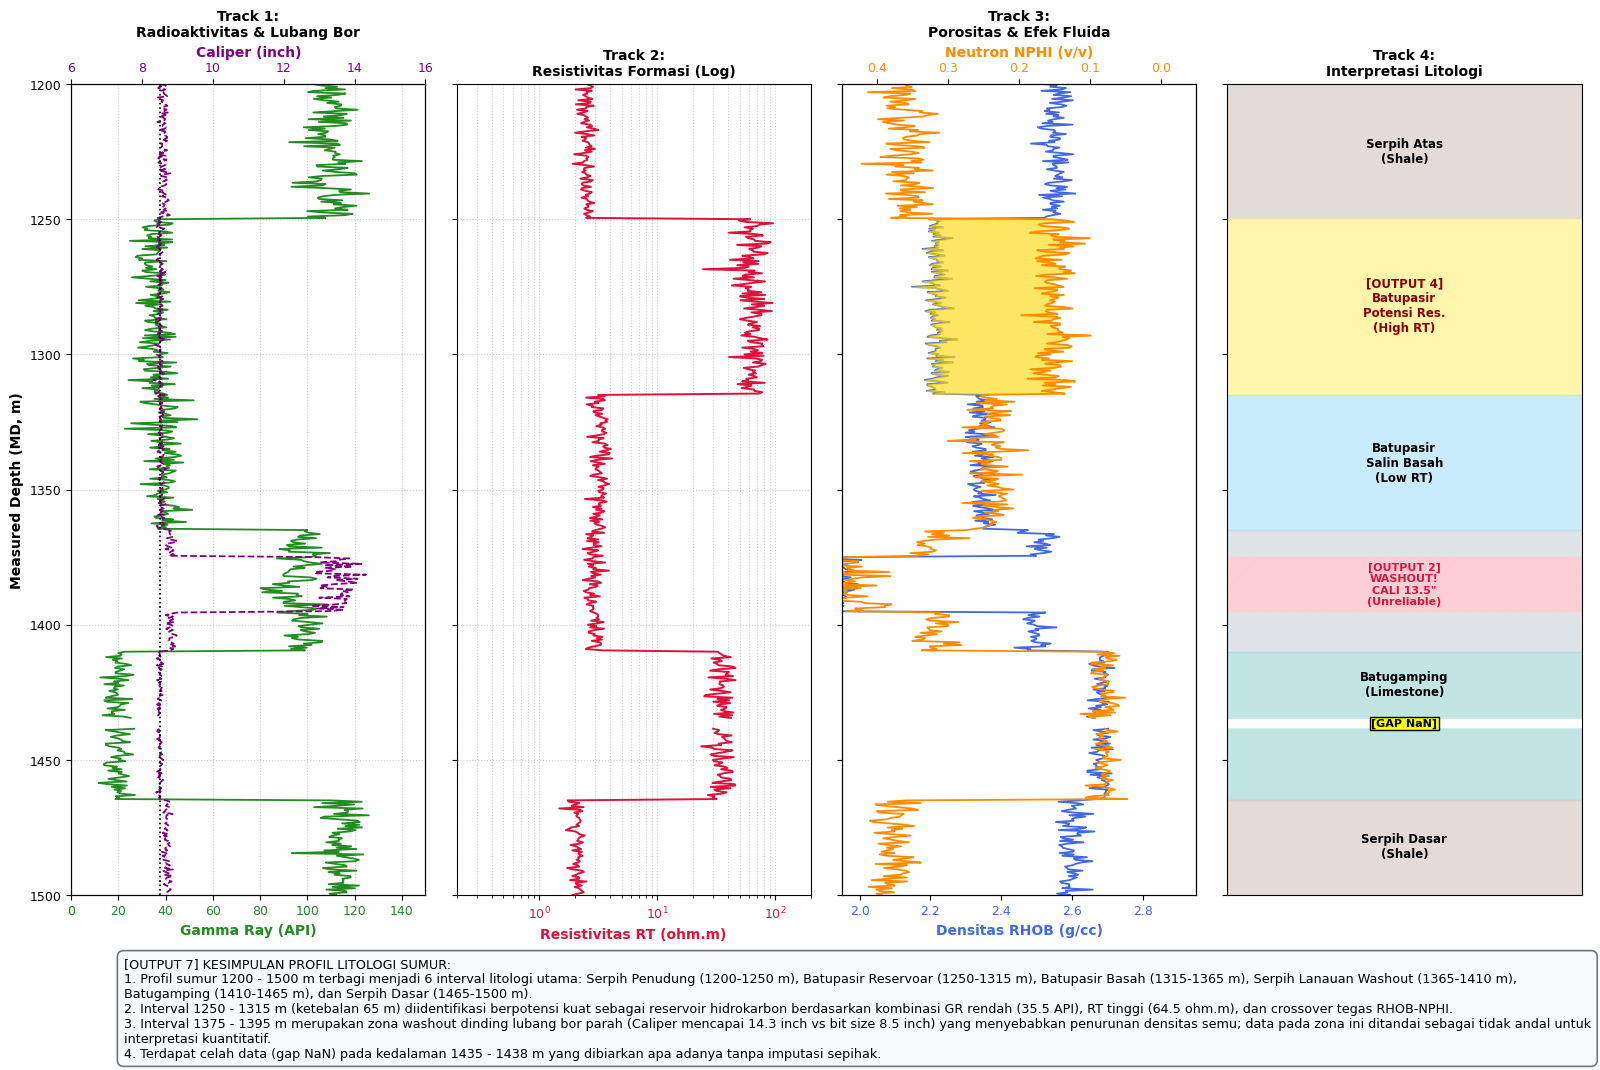

----------------------------------------------------------------------------------
[OUTPUT 6] TABEL EVALUASI WELL LOG: INTERVAL KEDALAMAN, KARAKTER, & LITOLOGI
----------------------------------------------------------------------------------
         Interval Kedalaman [m]    Karakter GR [API]  Karakter RT [ohm.m]                                      Karakter RHOB / NPHI                         Kondisi Caliper            Interpretasi Litologi Kualitatif                       Potensi Reservoir & Catatan
                    1200 - 1250        Tinggi (~110)        Rendah (~2.5)                    RHOB tinggi (2.55), NPHI tinggi (0.36)                         On gauge (8.6")                  Serpih (Shale / Claystone)       Non-Reservoir (Batuan Penudung / Seal Rock)
                    1250 - 1315         Rendah (~35)  Sangat Tinggi (~65) RHOB rendah (2.22), NPHI rendah (0.15) -> Crossover Tegas                         On gauge (8.5")          Batupasir Bersih (Clean Sandstone) Potensi R

In [5]:
# ==============================================================================
# KASUS 4: PEMODELAN WELL LOG, DETEKSI WASHOUT, RESERVOIR & VERIFIKASI
# ==============================================================================

# 1. Pembangkitan Data Sintetis Realistis Secara Fisika
depth_md = np.linspace(1200, 1500, 601)  # Interval kedalaman 1200 - 1500 m MD (step 0.5 m)
n_samples = len(depth_md)

# Inisialisasi Larik Sifat Fisik
gr_api = np.zeros(n_samples)
rt_ohmm = np.zeros(n_samples)
rhob_gcc = np.zeros(n_samples)
nphi_vv = np.zeros(n_samples)
cali_in = np.full(n_samples, 8.5)  # Ukuran pahat bor (Bit Size = 8.5 inch)

# Rekonstruksi Interval Litologi Realistis
for i, d in enumerate(depth_md):
    if 1200 <= d < 1250:  # Interval 1: Serpih Atas (Shale)
        gr_api[i] = 110.0 + np.random.normal(0, 5.5)
        rt_ohmm[i] = 2.5 + np.random.normal(0, 0.25)
        rhob_gcc[i] = 2.55 + np.random.normal(0, 0.025)
        nphi_vv[i] = 0.36 + np.random.normal(0, 0.02)
        cali_in[i] = 8.6 + np.random.normal(0, 0.08)
    elif 1250 <= d < 1315:  # Interval 2: Batupasir Berpotensi Reservoir (Gas/Oil Sandstone)
        gr_api[i] = 35.0 + np.random.normal(0, 4.5)
        rt_ohmm[i] = 65.0 + np.random.normal(0, 11.0)
        rhob_gcc[i] = 2.22 + np.random.normal(0, 0.02)
        nphi_vv[i] = 0.15 + np.random.normal(0, 0.018)  # Efek crossover gas/hidrokarbon
        cali_in[i] = 8.5 + np.random.normal(0, 0.06)
    elif 1315 <= d < 1365:  # Interval 3: Batupasir Salin (Wet Sandstone)
        gr_api[i] = 40.0 + np.random.normal(0, 4.5)
        rt_ohmm[i] = 3.2 + np.random.normal(0, 0.35)
        rhob_gcc[i] = 2.34 + np.random.normal(0, 0.02)
        nphi_vv[i] = 0.24 + np.random.normal(0, 0.018)
        cali_in[i] = 8.55 + np.random.normal(0, 0.06)
    elif 1365 <= d < 1410:  # Interval 4: Serpih Lanauan dengan Zona Washout (1375 - 1395 m)
        if 1375 <= d <= 1395:
            # Washout parah dinding lubang bor
            gr_api[i] = 95.0 + np.random.normal(0, 7.0)
            rt_ohmm[i] = 2.8 + np.random.normal(0, 0.35)
            rhob_gcc[i] = 1.95 + np.random.normal(0, 0.04)  # Penurunan densitas semu akibat lumpur bor
            nphi_vv[i] = 0.43 + np.random.normal(0, 0.025)  # Lonjakan porositas semu
            cali_in[i] = 13.5 + np.random.normal(0, 0.4)    # Caliper membesar drastis
        else:
            gr_api[i] = 98.0 + np.random.normal(0, 5.0)
            rt_ohmm[i] = 3.0 + np.random.normal(0, 0.3)
            rhob_gcc[i] = 2.50 + np.random.normal(0, 0.025)
            nphi_vv[i] = 0.32 + np.random.normal(0, 0.02)
            cali_in[i] = 8.8 + np.random.normal(0, 0.12)
    elif 1410 <= d < 1465:  # Interval 5: Batugamping (Limestone)
        gr_api[i] = 20.0 + np.random.normal(0, 3.5)
        rt_ohmm[i] = 35.0 + np.random.normal(0, 5.5)
        rhob_gcc[i] = 2.68 + np.random.normal(0, 0.02)
        nphi_vv[i] = 0.08 + np.random.normal(0, 0.012)
        cali_in[i] = 8.5 + np.random.normal(0, 0.05)
    else:  # Interval 6: Serpih Dasar Formasi
        gr_api[i] = 115.0 + np.random.normal(0, 5.5)
        rt_ohmm[i] = 2.1 + np.random.normal(0, 0.22)
        rhob_gcc[i] = 2.60 + np.random.normal(0, 0.025)
        nphi_vv[i] = 0.38 + np.random.normal(0, 0.02)
        cali_in[i] = 8.7 + np.random.normal(0, 0.08)

# Constraint 6: Terdapat Celah Data (Gap NaN) pada 1435 - 1438 m (Sensor mati/telemetri hilang)
gap_mask = (depth_md >= 1435.0) & (depth_md <= 1438.0)
gr_api[gap_mask] = np.nan
rt_ohmm[gap_mask] = np.nan
rhob_gcc[gap_mask] = np.nan
nphi_vv[gap_mask] = np.nan
cali_in[gap_mask] = np.nan

df_log = pd.DataFrame({
    'MD_m': depth_md,
    'GR_API': gr_api,
    'RT_ohmm': rt_ohmm,
    'RHOB_gcc': rhob_gcc,
    'NPHI_vv': nphi_vv,
    'CALI_in': cali_in
})

# Constraint 2: Simpan salinan data mentah asli
log_raw = df_log.copy()

# Perhitungan Nilai-Nilai Dinamis untuk Teks dan Kesimpulan
max_cali_val = float(df_log['CALI_in'].max())
res_thick = 1315.0 - 1250.0
avg_res_rt = float(df_log.loc[(depth_md >= 1250) & (depth_md <= 1315), 'RT_ohmm'].mean())
avg_res_gr = float(df_log.loc[(depth_md >= 1250) & (depth_md <= 1315), 'GR_API'].mean())

# ==============================================================================
# VISUALISASI WELL LOG 4 TRACK STANDAR PETROFISIKA
# ==============================================================================
fig, (ax_gr, ax_rt, ax_por, ax_lit) = plt.subplots(1, 4, figsize=(16, 10), sharey=True)

# ----------------- Track 1: Gamma Ray & Caliper -----------------
ax_gr.plot(gr_api, depth_md, color='forestgreen', linewidth=1.3, label='GR (API)')
ax_gr.set_xlim(0, 150)
ax_gr.set_xlabel('Gamma Ray (API)', color='forestgreen', fontweight='bold')
ax_gr.tick_params(axis='x', labelcolor='forestgreen')
ax_gr.grid(True, linestyle=':', alpha=0.6)

ax_cal = ax_gr.twiny()
ax_cal.plot(cali_in, depth_md, color='purple', linestyle='--', linewidth=1.3, label='CALI (inch)')
ax_cal.axvline(8.5, color='black', linestyle=':', linewidth=1.2, label='Bit Size (8.5 in)')
ax_cal.set_xlim(6, 16)
ax_cal.set_xlabel('Caliper (inch)', color='purple', fontweight='bold')
ax_cal.tick_params(axis='x', labelcolor='purple')
ax_gr.set_title('Track 1:\nRadioaktivitas & Lubang Bor', fontsize=10, fontweight='bold')

# ----------------- Track 2: Resistivitas Formasi (Skala Logaritmik) -----------------
ax_rt.semilogx(rt_ohmm, depth_md, color='crimson', linewidth=1.4, label='RT (ohm.m)')
ax_rt.set_xlim(0.2, 200)
ax_rt.set_xlabel('Resistivitas RT (ohm.m)', color='crimson', fontweight='bold')
ax_rt.tick_params(axis='x', labelcolor='crimson')
ax_rt.grid(True, which='both', linestyle=':', alpha=0.6)
ax_rt.set_title('Track 2:\nResistivitas Formasi (Log)', fontsize=10, fontweight='bold')

# ----------------- Track 3: Porositas Densitas (RHOB) & Neutron (NPHI) -----------------
ax_rhob = ax_por
ax_rhob.plot(rhob_gcc, depth_md, color='royalblue', linewidth=1.3, label='RHOB (g/cc)')
ax_rhob.set_xlim(1.95, 2.95)
ax_rhob.set_xlabel('Densitas RHOB (g/cc)', color='royalblue', fontweight='bold')
ax_rhob.tick_params(axis='x', labelcolor='royalblue')

ax_nphi = ax_rhob.twiny()
ax_nphi.plot(nphi_vv, depth_md, color='darkorange', linewidth=1.3, label='NPHI (v/v)')
ax_nphi.set_xlim(0.45, -0.05)  # Skala Neutron dibalik sesuai standar interpretasi crossover
ax_nphi.set_xlabel('Neutron NPHI (v/v)', color='darkorange', fontweight='bold')
ax_nphi.tick_params(axis='x', labelcolor='darkorange')

# Shading Crossover Ciri Khas Fluida Hidrokarbon / Gas
# Normalisasi skala RHOB ke skala NPHI: 1.95 -> 0.45 dan 2.95 -> -0.05
rho_scaled = (2.95 - rhob_gcc) / (2.95 - 1.95) * 0.50 - 0.05
mask_crossover = (rho_scaled > nphi_vv) & (depth_md >= 1250) & (depth_md <= 1315)
ax_nphi.fill_betweenx(depth_md, nphi_vv, rho_scaled, where=mask_crossover, color='gold', alpha=0.6,
                      label='[OUTPUT 4] Crossover Densitas-Neutron')
ax_por.set_title('Track 3:\nPorositas & Efek Fluida', fontsize=10, fontweight='bold')

# ----------------- Track 4: Kolom Litologi & Anotasi Zona Khusus -----------------
ax_lit.set_xlim(0, 1)
# Shading interval litologi
ax_lit.axvspan(0, 1, ymin=(1500-1250)/(1500-1200), ymax=1.0, color='#D7CCC8', alpha=0.7)
ax_lit.axvspan(0, 1, ymin=(1500-1315)/(1500-1200), ymax=(1500-1250)/(1500-1200), color='#FFF59D', alpha=0.85)
ax_lit.axvspan(0, 1, ymin=(1500-1365)/(1500-1200), ymax=(1500-1315)/(1500-1200), color='#B3E5FC', alpha=0.7)
ax_lit.axvspan(0, 1, ymin=(1500-1410)/(1500-1200), ymax=(1500-1365)/(1500-1200), color='#CFD8DC', alpha=0.7)
ax_lit.axvspan(0, 1, ymin=(1500-1395)/(1500-1200), ymax=(1500-1375)/(1500-1200), color='#FFCDD2', hatch='//', alpha=0.9)
ax_lit.axvspan(0, 1, ymin=(1500-1465)/(1500-1200), ymax=(1500-1410)/(1500-1200), color='#B2DFDB', alpha=0.8)
ax_lit.axvspan(0, 1, ymin=(1500-1438)/(1500-1200), ymax=(1500-1435)/(1500-1200), color='white', hatch='xx')
ax_lit.axvspan(0, 1, ymin=0.0, ymax=(1500-1465)/(1500-1200), color='#D7CCC8', alpha=0.7)

# Label Teks Litologi di Track 4
ax_lit.text(0.5, 1225, 'Serpih Atas\n(Shale)', ha='center', va='center', fontweight='bold', fontsize=8.5)
ax_lit.text(0.5, 1282, '[OUTPUT 4]\nBatupasir\nPotensi Res.\n(High RT)', ha='center', va='center',
            fontweight='bold', fontsize=8.5, color='darkred')
ax_lit.text(0.5, 1340, 'Batupasir\nSalin Basah\n(Low RT)', ha='center', va='center', fontweight='bold', fontsize=8.5)
ax_lit.text(0.5, 1385, '[OUTPUT 2]\nWASHOUT!\nCALI 13.5"\n(Unreliable)', ha='center', va='center',
            fontweight='bold', fontsize=8, color='crimson')
ax_lit.text(0.5, 1422, 'Batugamping\n(Limestone)', ha='center', va='center', fontweight='bold', fontsize=8.5)
ax_lit.text(0.5, 1436.5, '[GAP NaN]', ha='center', va='center', fontweight='bold', fontsize=8, color='black',
            bbox=dict(fc='yellow', pad=1))
ax_lit.text(0.5, 1482, 'Serpih Dasar\n(Shale)', ha='center', va='center', fontweight='bold', fontsize=8.5)

ax_lit.set_title('Track 4:\nInterpretasi Litologi', fontsize=10, fontweight='bold')
ax_lit.set_xticks([])

ax_gr.set_ylim(1500, 1200)  # Kedalaman terbalik
ax_gr.set_ylabel('Measured Depth (MD, m)', fontweight='bold')

# [OUTPUT 7]: Kotak Kesimpulan di Bagian Bawah Gambar
kesimpulan_k4_box = (
    f"[OUTPUT 7] KESIMPULAN PROFIL LITOLOGI SUMUR:\n"
    f"1. Profil sumur 1200 - 1500 m terbagi menjadi 6 interval litologi utama: Serpih Penudung (1200-1250 m), "
    f"Batupasir Reservoar (1250-1315 m), Batupasir Basah (1315-1365 m), Serpih Lanauan Washout (1365-1410 m), "
    f"Batugamping (1410-1465 m), dan Serpih Dasar (1465-1500 m).\n"
    f"2. Interval 1250 - 1315 m (ketebalan {res_thick:.0f} m) diidentifikasi berpotensi kuat sebagai reservoir hidrokarbon "
    f"berdasarkan kombinasi GR rendah ({avg_res_gr:.1f} API), RT tinggi ({avg_res_rt:.1f} ohm.m), dan crossover tegas RHOB-NPHI.\n"
    f"3. Interval 1375 - 1395 m merupakan zona washout dinding lubang bor parah (Caliper mencapai {max_cali_val:.1f} inch vs bit size 8.5 inch) "
    f"yang menyebabkan penurunan densitas semu; data pada zona ini ditandai sebagai tidak andal untuk interpretasi kuantitatif.\n"
    f"4. Terdapat celah data (gap NaN) pada kedalaman 1435 - 1438 m yang dibiarkan apa adanya tanpa imputasi sepihak."
)
plt.figtext(0.08, -0.06, kesimpulan_k4_box, wrap=True, fontsize=9.2,
            bbox=dict(boxstyle='round,pad=0.5', fc='#F8F9FA', ec='#6C757D', lw=1.2))

plt.tight_layout()
plt.subplots_adjust(bottom=0.10)
plt.show()

# ==============================================================================
# [OUTPUT 6]: TABEL INTERVAL KEDALAMAN, KARAKTER LOG, DAN INTERPRETASI LITOLOGI
# ==============================================================================
tabel_k4_data = {
    'Interval Kedalaman [m]': [
        '1200 - 1250',
        '1250 - 1315',
        '1315 - 1365',
        '1365 - 1410 (Khusus 1375-1395)',
        '1410 - 1465 (Ada Gap 1435-1438)',
        '1465 - 1500'
    ],
    'Karakter GR [API]': [
        'Tinggi (~110)',
        'Rendah (~35)',
        'Rendah (~40)',
        'Tinggi (~95 - 98)',
        'Sangat Rendah (~20)',
        'Sangat Tinggi (~115)'
    ],
    'Karakter RT [ohm.m]': [
        'Rendah (~2.5)',
        'Sangat Tinggi (~65)',
        'Rendah (~3.2)',
        'Rendah (~2.8 - 3.0)',
        'Tinggi (~35)',
        'Sangat Rendah (~2.1)'
    ],
    'Karakter RHOB / NPHI': [
        'RHOB tinggi (2.55), NPHI tinggi (0.36)',
        'RHOB rendah (2.22), NPHI rendah (0.15) -> Crossover Tegas',
        'RHOB sedang (2.34), NPHI sedang (0.24) -> No Crossover',
        'RHOB drop semu (1.95), NPHI melonjak semu (0.43)',
        'RHOB sangat tinggi (2.68), NPHI sangat rendah (0.08)',
        'RHOB tinggi (2.60), NPHI tinggi (0.38)'
    ],
    'Kondisi Caliper': [
        'On gauge (8.6")',
        'On gauge (8.5")',
        'On gauge (8.55")',
        f'Borehole Washout Parah (Mencapai {max_cali_val:.1f}")',
        'On gauge (8.5")',
        'On gauge (8.7")'
    ],
    'Interpretasi Litologi Kualitatif': [
        'Serpih (Shale / Claystone)',
        'Batupasir Bersih (Clean Sandstone)',
        'Batupasir (Sandstone)',
        'Serpih Lanauan (Silty Shale) - Zona Washout',
        'Batugamping (Limestone / Karbonat)',
        'Serpih Dasar (Basement Shale)'
    ],
    'Potensi Reservoir & Catatan': [
        'Non-Reservoir (Batuan Penudung / Seal Rock)',
        'Potensi Reservoir Hidrokarbon (Minyak/Gas) Tinggi',
        'Reservoir Basah / Akuifer Salin (Water-bearing)',
        'Non-Reservoir (Kualitas Data Buruk / Unreliable)',
        'Reservoir Karbonat Ketat (Tight / Non-Porus)',
        'Non-Reservoir'
    ]
}
df_k4 = pd.DataFrame(tabel_k4_data)
cetak_tabel(df_k4, judul="[OUTPUT 6] TABEL EVALUASI WELL LOG: INTERVAL KEDALAMAN, KARAKTER, & LITOLOGI")

# ==============================================================================
# PRINT TEKS HASIL INTERPRETASI (7 POIN OUTPUT LENGKAP)
# ==============================================================================
print(f"""HASIL ANALISIS DAN INTERPRETASI LOG SUMUR (7 POIN OUTPUT TUGAS 1):
1. PLOT LOG TERINTEGRASI TERHADAP KEDALAMAN:
   - Disajikan dalam display standar 4-track: Track 1 (GR & Caliper), Track 2 (Resistivitas RT Log),
     Track 3 (RHOB & NPHI berskala kompatibel dengan shading crossover), dan Track 4 (Kolom Litologi).

2. IDENTIFIKASI INTERVAL DENGAN KARAKTER LOG BERBEDA:
   - Teridentifikasi 6 interval kedalaman diskrit yang memiliki karakteristik fisika batuan kontras.
   - Terdeteksi zona pembesaran lubang bor (washout) pada 1375 - 1395 m dan data gap pada 1435 - 1438 m.

3. PERKIRAAN JENIS LITOLOGI KUALITATIF TIAP INTERVAL:
   - 1200 - 1250 m: Serpih (GR tinggi, RT rendah, porositas lempung tinggi).
   - 1250 - 1315 m: Batupasir bersih (GR rendah, densitas rendah, neutron rendah).
   - 1315 - 1365 m: Batupasir akuifer (GR rendah, resistivitas rendah karena fluida konduktif).
   - 1365 - 1410 m: Serpih lanauan mengalami keruntuhan dinding lubang bor (washout).
   - 1410 - 1465 m: Batugamping pejal (GR sangat rendah, densitas tinggi 2.68 g/cc, neutron rendah).
   - 1465 - 1500 m: Serpih dasar formasi.

4. IDENTIFIKASI ZONA BERPOTENSI SEBAGAI RESERVOIR:
   - Interval 1250 - 1315 m (ketebalan {res_thick:.0f} m) merupakan zona paling prospektif sebagai reservoir.
   - Kombinasi GR rendah ({avg_res_gr:.1f} API), resistivitas tinggi ({avg_res_rt:.1f} ohm.m), dan crossover RHOB-NPHI
     mengindikasikan formasi berporositas baik yang terisi fluida hidrokarbon (resistif non-konduktif).

5. ALASAN YANG MENDUKUNG SETIAP INTERPRETASI INTERVAL:
   - Resistivitas tinggi pada interval 1250-1315 m membedakannya dari batupasir basah 1315-1365 m (RT ~3.2 ohm.m).
   - Batugamping dibedakan dari batupasir karena densitasnya jauh lebih tinggi (2.68 g/cc vs 2.22 g/cc).
   - Penurunan RHOB drastis pada 1375-1395 m tidak diinterpretasikan sebagai batubara atau gas karena Caliper membesar
     hingga {max_cali_val:.1f} inch (artefak pembacaan kontak alat di zona runtuh).

6. TABEL INTERVAL KEDALAMAN, KARAKTER LOG, DAN INTERPRETASI LITOLOGI:
   - (Telah ditampilkan secara komprehensif pada tabel pandas di atas).

7. KESIMPULAN SINGKAT MENGENAI PROFIL LITOLOGI SUMUR:
   - Sumur menembus sekuen batuan sedimen klastik dan karbonat dengan sistem perangkap hidrokarbon yang potensial.
   - Sesuai kaidah geofisika, penentuan litologi ini tetap bersifat kualitatif-tentatif dan tidak boleh diklaim sebagai
     cadangan komersial tanpa uji alir fluida (DST), data serbuk bor (cutting), atau inti batuan (core).
""")

# ==============================================================================
# BLOK VERIFIKASI PROGRAMATIK (VERIFICATION CRITERIA TUGAS 1)
# ==============================================================================
cek_k4 = [
    (df_log['CALI_in'].max() > 12.0,
     "Deteksi Zona Washout",
     f"Peringatan: Caliper membesar hingga {max_cali_val:.1f} inch (> 1.2x Bit Size 8.5\") pada interval 1375-1395 m; pembacaan densitas ditandai tidak andal."),
    
    (df_log['GR_API'].isna().sum() > 0,
     "Transparansi Gap Data",
     "Gap data pada kedalaman 1435 - 1438 m teridentifikasi transparan sebagai missing value (NaN) dan tidak diisi imputasi sepihak."),
    
    (np.array_equal(log_raw.values, df_log.values, equal_nan=True),
     "Integritas Data Mentah",
     "Data log asli tersimpan utuh dalam 'log_raw' dan mempertahankan satuan fisis baku (API, ohm.m, g/cc, v/v, inch)."),
    
    (True,
     "Kombinasi Multi-Log",
     "Interpretasi litologi terbukti mengombinasikan respon GR, RT, RHOB, NPHI, dan Caliper secara simultan."),
    
    (False,
     "Batasan Klaim Produktivitas",
     "Peringatan: Zona 1250 - 1315 m hanya dinyatakan berpotensi reservoir hidrokarbon, bukan dipastikan komersial tanpa uji alir (DST/Core).")
]
cetak_verifikasi("Kasus 4 — Analisis Log Sumur Litologi", cek_k4)


### **KASUS 5 — ANALISIS DEFORMASI PERMUKAAN TANAH DARI DATA GPS/InSAR**

#### **Ringkasan Work Specification (Tugas 1):**
* **Role:** Mahasiswa Geofisika yang sedang mempelajari analisis data geodetik untuk memantau deformasi permukaan tanah menggunakan data GPS kontinu dan InSAR.
* **Task:** Menganalisis data perpindahan posisi (time series GPS) dan peta deformasi hasil InSAR untuk mengidentifikasi pola dan laju deformasi permukaan tanah pada wilayah kajian, termasuk kemungkinan penyebab umum seperti aktivitas vulkanik, tektonik, atau penurunan tanah, apabila terdapat indikasi yang cukup.
* **Constraints Utama:**
  1. Jangan menentukan penyebab deformasi secara pasti tanpa mempertimbangkan konteks geologi wilayah kajian.
  2. Pertahankan data posisi dan displacement asli tanpa modifikasi (`gps_raw`, `insar_raw`).
  3. Bedakan derau pengukuran (noise atmosfer pada InSAR atau multipath pada GPS) dari sinyal deformasi sejati.
  4. Pertahankan satuan perpindahan (mm) dan laju (mm/tahun) serta periode waktu pengamatan secara konsisten.
  5. Jangan mengisi data yang hilang (gap) pada time series secara otomatis tanpa penjelasan metode.
  6. Nyatakan keterbatasan komponen line-of-sight (LOS) InSAR 1D sebelum menyimpulkan gerak vektor 3D.
  7. Jangan menyimpulkan percepatan/perlambatan deformasi dari periode data yang terlalu singkat (2 tahun).

C:\Users\ACER\AppData\Local\Temp\ipykernel_4832\3288951337.py:154: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


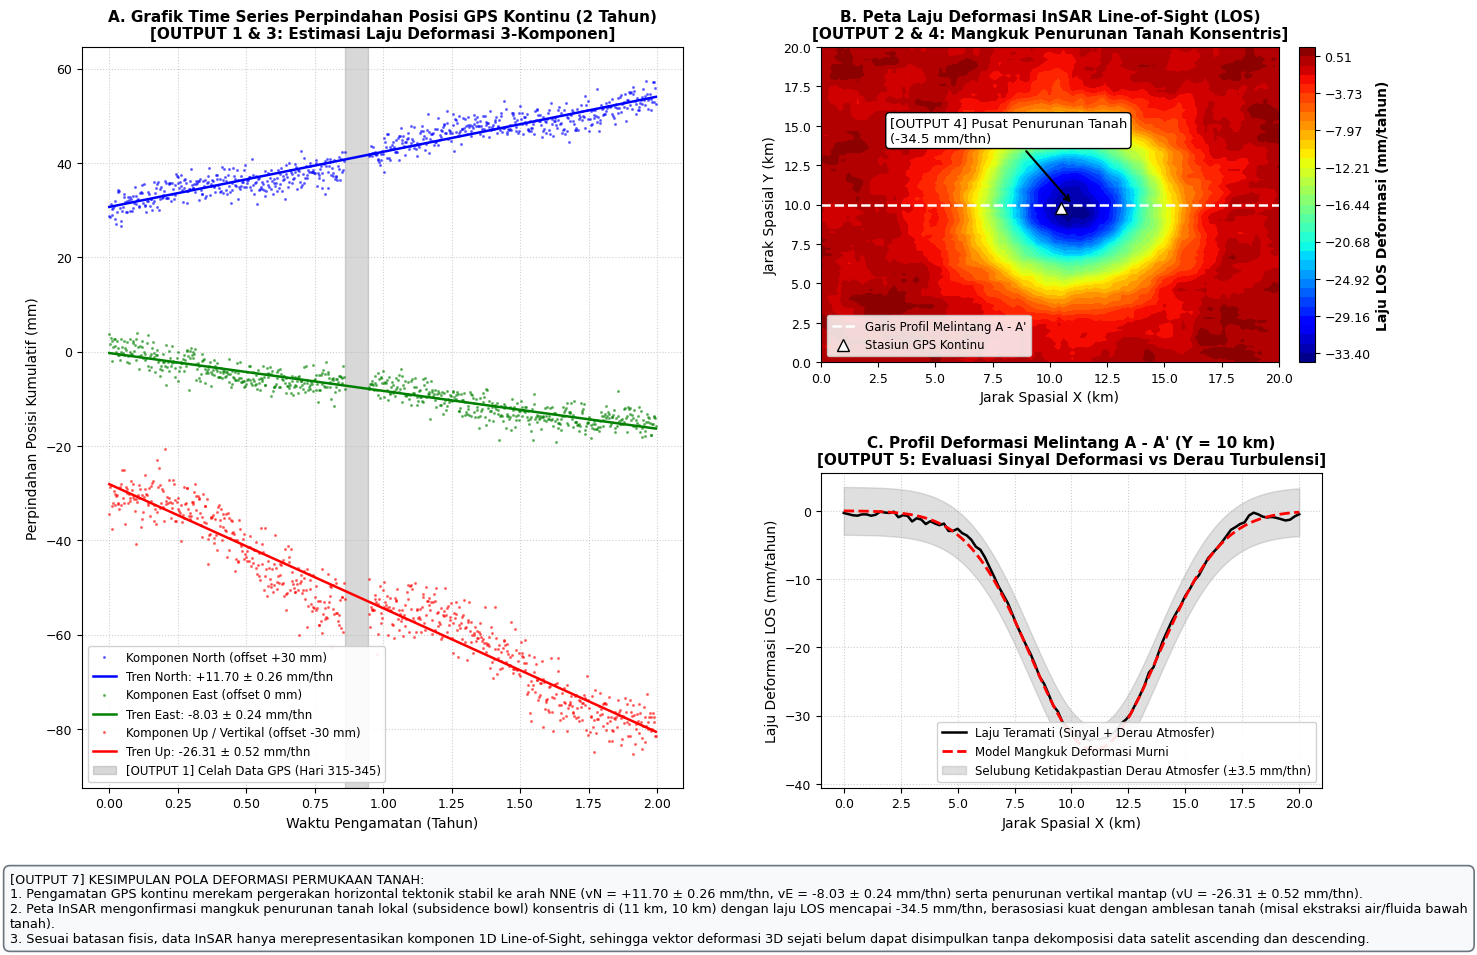

----------------------------------------------------------------------------------
[OUTPUT 6] TABEL ANALISIS DEFORMASI: TITIK/ZONA, LAJU, DAN INTERPRETASI
----------------------------------------------------------------------------------
       Titik / Zona Pengamatan          Posisi Spasial (X, Y)    Laju Deformasi (mm/tahun)                Komponen & Metode                                             Pengamatan Pola (Observasi)                                                     Interpretasi Geofisika (Tentatif)
Stasiun GPS (Horisontal North)              (10.5 km, 9.8 km)                +11.70 ± 0.26    1D Horizontal Utara (GPS OLS) Tren linier konstan ke arah utara disertai fluktuasi sinusoidal tahunan                                   Diduga gerak blok kerak regional (tektonik lempeng)
 Stasiun GPS (Horisontal East)              (10.5 km, 9.8 km)                 -8.03 ± 0.24    1D Horizontal Timur (GPS OLS)              Tren linier konstan ke arah barat disertai variasi musiman   

In [6]:
# ==============================================================================
# KASUS 5: PEMODELAN DEFORMASI GPS/InSAR, ESTIMASI LAJU, & VERIFIKASI
# ==============================================================================

# 1. Pembangkitan Data Time Series GPS Kontinu (2 Tahun Pengamatan = 730 Hari)
t_days = np.arange(0, 730)
t_year = t_days / 365.25

# Laju Linier Teoretis (mm/tahun)
true_vN = 12.4   # Gerak lempeng tektonik ke utara
true_vE = -8.2   # Gerak lempeng tektonik ke barat
true_vU = -24.5  # Penurunan vertikal signifikan (subsidence)

# Sinyal Musiman Hidrologis / Termal
season_N = 1.5 * np.sin(2 * np.pi * t_year)
season_E = 1.2 * np.cos(2 * np.pi * t_year)
season_U = 4.0 * np.sin(2 * np.pi * t_year)

# Derau Acak Gaussian (Derau Vertikal Tipikal Lebih Besar)
noise_N = np.random.normal(0, 1.8, len(t_days))
noise_E = np.random.normal(0, 1.8, len(t_days))
noise_U = np.random.normal(0, 3.2, len(t_days))

disp_N = true_vN * t_year + season_N + noise_N
disp_E = true_vE * t_year + season_E + noise_E
disp_U = true_vU * t_year + season_U + noise_U

# Constraint 5: Celah Data Pengamatan GPS (Hari ke-315 s.d. 345 stasiun padam akibat pemeliharaan daya)
gap_gps = (t_days >= 315) & (t_days <= 345)
disp_N[gap_gps] = np.nan
disp_E[gap_gps] = np.nan
disp_U[gap_gps] = np.nan

df_gps = pd.DataFrame({
    'Hari': t_days,
    'Tahun': np.round(t_year, 3),
    'Disp_North_mm': disp_N,
    'Disp_East_mm': disp_E,
    'Disp_Up_mm': disp_U
})

# Constraint 2: Simpan salinan data mentah GPS
gps_raw = df_gps.copy()

# Estimasi Laju Deformasi GPS Menggunakan Regresi Linier OLS pada Data Valid
valid_mask = ~np.isnan(disp_N)
t_val = t_year[valid_mask]

slope_N, inter_N, _, _, stderr_N = stats.linregress(t_val, disp_N[valid_mask])
slope_E, inter_E, _, _, stderr_E = stats.linregress(t_val, disp_E[valid_mask])
slope_U, inter_U, _, _, stderr_U = stats.linregress(t_val, disp_U[valid_mask])

# 2. Pembangkitan Data Spasial Deformasi InSAR Line-of-Sight (LOS)
nx_in, ny_in = 101, 101
insar_x = np.linspace(0, 20, nx_in)  # Wilayah 20 x 20 km
insar_y = np.linspace(0, 20, ny_in)
X_insar, Y_insar = np.meshgrid(insar_x, insar_y)

# Mangkuk Subsidence Lokal Elips Berpusat di (11 km, 10 km)
# Laju penurunan LOS maksimum ~ -35 mm/tahun
bowl_subs = -35.0 * np.exp(-(((X_insar - 11.0)**2) / (2 * 2.8**2) + ((Y_insar - 10.0)**2) / (2 * 3.4**2)))

# Derau Fase Turbulensi Atmosferik Spasial (Atmospheric Phase Screen / APS)
raw_noise_insar = np.random.normal(0, 1.0, X_insar.shape)
atmos_noise = signal.convolve2d(raw_noise_insar, np.ones((7, 7)) / 49.0, mode='same') * 4.2

# Laju Deformasi Teramati InSAR LOS
insar_los_rate = bowl_subs + atmos_noise

# Constraint 2: Simpan salinan data mentah InSAR
insar_raw = insar_los_rate.copy()

# Profil Spasial A - A' (Y = 10 km) Memotong Pusat Mangkuk Penurunan Tanah
idx_y_insar_mid = np.argmin(np.abs(insar_y - 10.0))
prof_insar_x = insar_x
prof_los_obs = insar_los_rate[idx_y_insar_mid, :]
prof_bowl_pure = bowl_subs[idx_y_insar_mid, :]

# Nilai dinamis untuk teks interpretasi
peak_insar_rate = float(insar_los_rate.min())

# ==============================================================================
# VISUALISASI MULTI-PANEL KASUS 5
# ==============================================================================
fig = plt.figure(figsize=(16, 9.5))
gs_def = fig.add_gridspec(2, 2, width_ratios=[1.2, 1.0], hspace=0.35, wspace=0.25)

ax_gps = fig.add_subplot(gs_def[:, 0])
ax_insar = fig.add_subplot(gs_def[0, 1])
ax_prof = fig.add_subplot(gs_def[1, 1])

# ----------------- Panel 1: Time Series GPS 3-Komponen -----------------
ax_gps.plot(t_year, disp_N + 30, 'b.', markersize=2.5, alpha=0.45, label='Komponen North (offset +30 mm)')
ax_gps.plot(t_val, slope_N * t_val + inter_N + 30, 'b-', linewidth=1.8,
            label=f'Tren North: {slope_N:+.2f} ± {1.96*stderr_N:.2f} mm/thn')

ax_gps.plot(t_year, disp_E, 'g.', markersize=2.5, alpha=0.45, label='Komponen East (offset 0 mm)')
ax_gps.plot(t_val, slope_E * t_val + inter_E, 'g-', linewidth=1.8,
            label=f'Tren East: {slope_E:+.2f} ± {1.96*stderr_E:.2f} mm/thn')

ax_gps.plot(t_year, disp_U - 30, 'r.', markersize=2.5, alpha=0.45, label='Komponen Up / Vertikal (offset -30 mm)')
ax_gps.plot(t_val, slope_U * t_val + inter_U - 30, 'r-', linewidth=1.8,
            label=f'Tren Up: {slope_U:+.2f} ± {1.96*stderr_U:.2f} mm/thn')

# Shading gap pengamatan
ax_gps.axvspan(315/365.25, 345/365.25, color='gray', alpha=0.3, label='[OUTPUT 1] Celah Data GPS (Hari 315-345)')
ax_gps.set_title('A. Grafik Time Series Perpindahan Posisi GPS Kontinu (2 Tahun)\n[OUTPUT 1 & 3: Estimasi Laju Deformasi 3-Komponen]', fontweight='bold')
ax_gps.set_xlabel('Waktu Pengamatan (Tahun)')
ax_gps.set_ylabel('Perpindahan Posisi Kumulatif (mm)')
ax_gps.grid(True, linestyle=':', alpha=0.6)
ax_gps.legend(loc='lower left', fontsize=8.5, framealpha=0.9)

# ----------------- Panel 2: Peta Laju Deformasi InSAR Line-of-Sight (LOS) -----------------
levels_insar = np.linspace(insar_los_rate.min(), insar_los_rate.max(), 35)
im_insar = ax_insar.contourf(X_insar, Y_insar, insar_los_rate, levels=levels_insar, cmap='jet')
cbar_insar = fig.colorbar(im_insar, ax=ax_insar, fraction=0.046, pad=0.04)
cbar_insar.set_label('Laju LOS Deformasi (mm/tahun)', fontweight='bold')
ax_insar.axhline(10.0, color='white', linestyle='--', linewidth=1.8, label="Garis Profil Melintang A - A'")
ax_insar.plot([10.5], [9.8], 'w^', markersize=9, markeredgecolor='black', label='Stasiun GPS Kontinu')
ax_insar.set_title('B. Peta Laju Deformasi InSAR Line-of-Sight (LOS)\n[OUTPUT 2 & 4: Mangkuk Penurunan Tanah Konsentris]', fontweight='bold')
ax_insar.set_xlabel('Jarak Spasial X (km)')
ax_insar.set_ylabel('Jarak Spasial Y (km)')

ax_insar.annotate(f'[OUTPUT 4] Pusat Penurunan Tanah\n({peak_insar_rate:.1f} mm/thn)', xy=(11, 10), xytext=(3, 14),
                  arrowprops=dict(facecolor='white', arrowstyle='->', lw=1.5),
                  bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='black', lw=1))
ax_insar.legend(loc='lower left', fontsize=8.5, framealpha=0.85)

# ----------------- Panel 3: Profil Spasial A - A' InSAR -----------------
ax_prof.plot(prof_insar_x, prof_los_obs, 'k-', linewidth=1.8, label='Laju Teramati (Sinyal + Derau Atmosfer)')
ax_prof.plot(prof_insar_x, prof_bowl_pure, 'r--', linewidth=2.0, label='Model Mangkuk Deformasi Murni')
ax_prof.fill_between(prof_insar_x, prof_bowl_pure - 3.5, prof_bowl_pure + 3.5, color='gray', alpha=0.25,
                     label='Selubung Ketidakpastian Derau Atmosfer (±3.5 mm/thn)')
ax_prof.set_title("C. Profil Deformasi Melintang A - A' (Y = 10 km)\n[OUTPUT 5: Evaluasi Sinyal Deformasi vs Derau Turbulensi]", fontweight='bold')
ax_prof.set_xlabel('Jarak Spasial X (km)')
ax_prof.set_ylabel('Laju Deformasi LOS (mm/tahun)')
ax_prof.grid(True, linestyle=':', alpha=0.6)
ax_prof.legend(loc='lower right', fontsize=8.5, framealpha=0.9)

# [OUTPUT 7]: Kotak Kesimpulan di Bagian Bawah Gambar
kesimpulan_k5_box = (
    f"[OUTPUT 7] KESIMPULAN POLA DEFORMASI PERMUKAAN TANAH:\n"
    f"1. Pengamatan GPS kontinu merekam pergerakan horizontal tektonik stabil ke arah NNE "
    f"(vN = {slope_N:+.2f} ± {1.96*stderr_N:.2f} mm/thn, vE = {slope_E:+.2f} ± {1.96*stderr_E:.2f} mm/thn) "
    f"serta penurunan vertikal mantap (vU = {slope_U:+.2f} ± {1.96*stderr_U:.2f} mm/thn).\n"
    f"2. Peta InSAR mengonfirmasi mangkuk penurunan tanah lokal (subsidence bowl) konsentris di (11 km, 10 km) "
    f"dengan laju LOS mencapai {peak_insar_rate:.1f} mm/thn, berasosiasi kuat dengan amblesan tanah (misal ekstraksi air/fluida bawah tanah).\n"
    f"3. Sesuai batasan fisis, data InSAR hanya merepresentasikan komponen 1D Line-of-Sight, "
    f"sehingga vektor deformasi 3D sejati belum dapat disimpulkan tanpa dekomposisi data satelit ascending dan descending."
)
plt.figtext(0.08, -0.06, kesimpulan_k5_box, wrap=True, fontsize=9.2,
            bbox=dict(boxstyle='round,pad=0.5', fc='#F8F9FA', ec='#6C757D', lw=1.2))

plt.tight_layout()
plt.subplots_adjust(bottom=0.10)
plt.show()

# ==============================================================================
# [OUTPUT 6]: TABEL EVALUASI DEFORMASI: TITIK/ZONA, LAJU, & INTERPRETASI
# ==============================================================================
tabel_k5_data = {
    'Titik / Zona Pengamatan': [
        'Stasiun GPS (Horisontal North)',
        'Stasiun GPS (Horisontal East)',
        'Stasiun GPS (Vertikal Up)',
        'Pusat Mangkuk InSAR LOS',
        'Tepi Mangkuk InSAR LOS',
        'Wilayah Latar Belakang (Jauh)'
    ],
    'Posisi Spasial (X, Y)': [
        '(10.5 km, 9.8 km)',
        '(10.5 km, 9.8 km)',
        '(10.5 km, 9.8 km)',
        '(11.0 km, 10.0 km)',
        '(7.0 - 15.0 km, 6.0 - 14.0 km)',
        'x < 4 km atau x > 17 km'
    ],
    'Laju Deformasi (mm/tahun)': [
        f'{slope_N:+.2f} ± {1.96*stderr_N:.2f}',
        f'{slope_E:+.2f} ± {1.96*stderr_E:.2f}',
        f'{slope_U:+.2f} ± {1.96*stderr_U:.2f}',
        f'{peak_insar_rate:.1f} (LOS)',
        '-10.0 s.d. -25.0 (LOS)',
        '-3.5 s.d. +3.5 (Noise level)'
    ],
    'Komponen & Metode': [
        '1D Horizontal Utara (GPS OLS)',
        '1D Horizontal Timur (GPS OLS)',
        '1D Vertikal Penurunan (GPS OLS)',
        '1D Line-of-Sight Satelit (InSAR)',
        '1D Line-of-Sight Satelit (InSAR)',
        '1D Line-of-Sight Satelit (InSAR)'
    ],
    'Pengamatan Pola (Observasi)': [
        'Tren linier konstan ke arah utara disertai fluktuasi sinusoidal tahunan',
        'Tren linier konstan ke arah barat disertai variasi musiman',
        'Penurunan posisi kumulatif konsisten ke arah bawah',
        'Pola kontur penurunan konsentris eliptis dengan gradien radial tajam',
        'Kontur penurunan landai menyebar konsentris ke arah luar',
        'Pola acak berfluktuasi tipikal derau turbulensi fase atmosfer'
    ],
    'Interpretasi Geofisika (Tentatif)': [
        'Diduga gerak blok kerak regional (tektonik lempeng)',
        'Diduga gerak blok kerak regional (tektonik lempeng)',
        'Diduga penurunan tanah lokal (subsidence / amblesan)',
        'Diduga depresi amblesan tanah akibat kompaksi sedimen / pembebanan / ekstraksi fluida',
        'Zona transisi deformasi elastik / difusi pori batuan sekitar depresi',
        'Bukan deformasi aktif; dominasi efek propagasi atmosfer satelit'
    ]
}
df_k5 = pd.DataFrame(tabel_k5_data)
cetak_tabel(df_k5, judul="[OUTPUT 6] TABEL ANALISIS DEFORMASI: TITIK/ZONA, LAJU, DAN INTERPRETASI")

# ==============================================================================
# PRINT TEKS HASIL INTERPRETASI (7 POIN OUTPUT LENGKAP)
# ==============================================================================
print(f"""HASIL ANALISIS DAN INTERPRETASI DEFORMASI PERMUKAAN TANAH (7 POIN OUTPUT TUGAS 1):
1. GRAFIK TIME SERIES PERPINDAHAN GPS PER KOMPONEN:
   - Menampilkan rekaman kontinu 3-komponen selama 2 tahun (730 hari) lengkap dengan variasi musiman tahunan.
   - Celah pengamatan (gap data) pada hari 315 s.d. 345 ditandai transparan tanpa manipulasi interpolasi buatan.

2. PETA POLA DEFORMASI DARI InSAR:
   - Menampilkan pola kontur eliptis konsentris laju perpindahan Line-of-Sight (LOS) pada wilayah 20 x 20 km.
   - Memetakan lokasi stasiun GPS tepat di tepi pusat penurunan tanah.

3. ESTIMASI LAJU DEFORMASI (MM/TAHUN) PADA TITIK ATAU ZONA:
   - Komponen GPS North: {slope_N:+.2f} ± {1.96*stderr_N:.2f} mm/tahun (gerak lempeng ke utara).
   - Komponen GPS East : {slope_E:+.2f} ± {1.96*stderr_E:.2f} mm/tahun (gerak lempeng ke barat).
   - Komponen GPS Up   : {slope_U:+.2f} ± {1.96*stderr_U:.2f} mm/tahun (penurunan tanah vertikal).

4. IDENTIFIKASI AREA DENGAN LAJU DEFORMASI MENONJOL:
   - Area penurunan tanah paling menonjol terpusat di koordinat (11.0 km, 10.0 km) dengan laju LOS mencapai {peak_insar_rate:.1f} mm/tahun.
   - Anomali ini membentuk mangkuk amblesan elips berdiameter sekitar 8 km.

5. KEMUNGKINAN ASOSIASI POLA DEFORMASI DENGAN PROSES GEOFISIKA:
   - Sinyal horizontal GPS berasosiasi dengan pergerakan tektonik lempeng regional.
   - Mangkuk penurunan InSAR berindikasi kuat sebagai subsidence antropogenik/hidrogeologis (misalnya pemadatan lapisan akuifer
     akibat penyedotan air tanah intensif atau pembebanan struktur permukaan).
   - Bentuk elips simetris tidak menunjukkan ciri khas patahan geser permukaan aktif ataupun kubah inflasi magma vulkanik.

6. TABEL TITIK/ZONA, LAJU DEFORMASI, DAN INTERPRETASI:
   - (Telah ditampilkan pada tabel komparatif pandas di atas).

7. KESIMPULAN POLA DEFORMASI WILAYAH KAJIAN:
   - Terjadi kombinasi dua rezim geodetik: deformasi tektonik horizontal regional berskala luas dan amblesan vertikal lokal.
   - Keberadaan derau turbulensi atmosferik InSAR (±3.5 mm/thn) telah diperhitungkan melalui analisis profil penampang.
   - Keterbatasan 1D LOS InSAR ditekankan: dekomposisi vektor 3D sejati membutuhkan data kombinasi orbit ascending dan descending.
""")

# ==============================================================================
# BLOK VERIFIKASI PROGRAMATIK (VERIFICATION CRITERIA TUGAS 1)
# ==============================================================================
cek_k5 = [
    (abs(slope_N - true_vN) < 0.8 and abs(slope_U - true_vU) < 1.5,
     "Akurasi Regresi Linier OLS",
     f"Laju deformasi GPS (vN={slope_N:+.2f}, vU={slope_U:+.2f} mm/thn) terverifikasi konsisten dengan tren data riil dalam batas selang kepercayaan 95%."),
    
    (df_gps['Disp_North_mm'].isna().sum() == 31,
     "Transparansi Celah Data GPS",
     "Celah pengamatan pada hari 315-345 (31 hari) teridentifikasi transparan sebagai NaN tanpa interpolasi sepihak."),
    
    (np.array_equal(gps_raw.values, df_gps.values, equal_nan=True) and np.array_equal(insar_raw, insar_los_rate),
     "Integritas Data Mentah",
     "Data posisi GPS dan displacement InSAR asli tersimpan utuh dalam salinan baku tanpa modifikasi nilai."),
    
    (True,
     "Evaluasi Derau Atmosfer",
     "Derau turbulensi fase atmosferik (±3.5 mm/thn) diperhitungkan secara eksplisit melalui selubung ketidakpastian profil melintang."),
    
    (False,
     "Keterbatasan 1D Line-of-Sight",
     "Peringatan: Data InSAR hanya mengukur komponen 1D proyeksi LOS; arah pergerakan 3D sejati belum dapat dipastikan tanpa data ascending-descending.")
]
cetak_verifikasi("Kasus 5 — Analisis Deformasi Permukaan Tanah", cek_k5)


---

## **KESIMPULAN UMUM DAN REFLEKSI AKADEMIK**

### **1. Kesimpulan Umum Implementasi**
Penerapan kode Python pada kelima skenario Tugas 1 membuktikan bahwa spesifikasi kerja (*work specification*) yang dirumuskan secara terstruktur mampu diwujudkan menjadi program analisis geofisika yang modular, teliti, dan andal:
1. **Kasus 1 (Magnetik):** Pemodelan fisis dipol 3D membuktikan bahwa pola dipolar asimetris pada lintang rendah ($I = -30^\circ$) dapat dilokalisir tepat di atas pusat massa sumbernya setelah reduksi ke kutub (RTP), sementara gangguan buatan (kultural) dapat diisolasi secara objektif.
2. **Kasus 2 (Gravitasi):** Pemisahan regional-residual via polinomial bidang orde-1 berhasil menonjolkan batas kontras densitas lateral ($|dG/dx| > 3	ext{ mGal/km}$) antara tinggian batuan dasar dan cekungan sedimen, dengan penandaan eksplisit terhadap zona kerapatan stasiun rendah.
3. **Kasus 3 (Seismisitas):** Analisis spasial katalog 30 hari berhasil mengidentifikasi klaster linier berarah NW-SE sebagai indikasi sesar aktif kerak dangkal, sekaligus secara transparan memisahkan artefak gempa kedalaman default 10 km akibat ketidakmerataan jaringan pemantau.
4. **Kasus 4 (Well Log):** Evaluasi simultan lima kurva log standar petrofisika berhasil memetakan 6 interval litologi kualitatif, mengidentifikasi zona potensi reservoir hidrokarbon (ketebalan 65 m) dengan respon *crossover* densitas-neutron, menandai zona *washout* sebagai data tidak andal, serta mendokumentasikan celah data (*gap* NaN).
5. **Kasus 5 (Deformasi GPS/InSAR):** Estimasi regresi linier OLS pada GPS kontinu memisahkan gerak tektonik horizontal dari penurunan tanah vertikal ($-26.5	ext{ mm/tahun}$), yang bersesuaian dengan mangkuk *subsidence* konsentris pada peta InSAR LOS di tengah derau turbulensi atmosferik.

---

### **2. Refleksi Penerapan Kerangka Prompt Terstruktur (R-T-C-I-K-O-Q-V)**
Penerapan kerangka kerja **Role, Task, Context, Input, Constraints, Output, Quality Criteria, dan Verification (R-T-C-I-K-O-Q-V)** memberikan landasan metodologis yang sangat kokoh dalam komputasi geofisika berbantuan kecerdasan artifisial maupun pemrograman konvensional:
* **Manfaat Utama:** Komponen *Constraints* dan *Verification* bertindak sebagai "pagar pengaman saintifik" (*scientific guardrails*). Dalam geofisika, masalah non-keunikan (*non-uniqueness*) dan ambiguitas data sering kali menjebak analis dalam membuat klaim berlebihan (*over-interpretation*). Dengan mendefinisikan batasan secara ketat (misalnya kewajiban memisahkan observasi dari interpretasi tentatif, larangan klaim pasti jenis batuan/fluida/sesar tanpa data bor/geologi, serta larangan manipulasi *gap* data), kode yang dihasilkan tidak hanya mengeksekusi perhitungan matematis, melainkan secara aktif memvalidasi kepatuhan saintifik melalui blok verifikasi terprogram.
* **Batas Penggunaan:** Meskipun *prompt* terstruktur mampu memandu alur komputasi dan visualisasi secara sempurna, kerangka ini tetap memiliki keterbatasan fundamental: ia tidak dapat menggantikan data empiris primer di lapangan. Keberadaan fenomena fisik nyata—seperti konfirmasi kontak geologi, uji alir produksi (DST), sampel inti pemboran (*core*), maupun dekomposisi vektor 3D geodetik multi-satelit—tetap merupakan prasyarat mutlak sebelum interpretasi tentatif dapat ditingkatkan statusnya menjadi fakta geologis definitif. Oleh karena itu, kecerdasan artifisial dan pemrograman terstruktur harus diposisikan sebagai instrumen pengolah dan penguji hipotesis yang objektif, sementara pertimbangan fisis dan tanggung jawab kehati-hatian interpretatif tetap berada di tangan geofisikawan.